# 02 — Supervisado: cómo entrenamos y evaluamos los modelos

En este notebook vamos a entrenar cuatro modelos y revisar qué nos dicen sus resultados. Primero armamos los datos; después comparamos dos formas de evaluarlos; por último, miramos las métricas y sus límites.

Vas a encontrar nombres usados en las prácticas (`X_train`, `X_test`, `modelo.fit`, `confusion_matrix`, `roc_curve`). Los vamos a usar dentro del problema del trabajo, no como pasos aislados.

**Recorrido:**

1. Preparar las variables de entrada (`X`) y la respuesta correcta (`y`).
2. Comparar una validación cruzada aleatoria con LOSO, que reserva un escenario completo.
3. Reducir las variables y comprobar cuáles parecen influir en el resultado.
4. Comparar Random Forest, SVM, XGBoost y CatBoost sobre la reducción `block_pca`.
5. Leer las métricas de un escenario.
6. Cargar el modelo guardado y usarlo como en producción.


## Antes de empezar: si lo abrís en Google Colab

Este notebook vive en el repo y lee `datasets/`, `src/`, `resultados/` y `modelos/` desde la raíz del proyecto. En Colab esos archivos no existen, así que la celda de abajo clona el repo en `/content/data4cyber` y se para ahí.

**Cómo abrirlo:**

1. En Colab: *Archivo → Abrir notebook → GitHub*, pegá la URL del repo y elegí el notebook.
2. Ejecutá la primera celda. Clona el repo (una sola vez por sesión) y queda listo para correr.

Fuera de Colab la celda no hace nada.


In [2]:
# --- Preparar el entorno: solo hace algo si estás en Google Colab ---
import os
import subprocess
import sys
from pathlib import Path

REPO = "https://github.com/maxiricalde/data4cyber.git"
DESTINO = Path("/content/data4cyber")

try:
    import google.colab  # noqa: F401

    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    # CatBoost no viene preinstalado en Colab; lo instalamos una sola vez.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "catboost"], check=False)
    # Una sola vez por sesión: clonar el repo y pararse en su raíz.
    if not (DESTINO / "src" / "data.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, str(DESTINO)], check=True)
    os.chdir(DESTINO)
    print("proyecto en:", os.getcwd())
else:
    print("corriendo local: no hay nada que preparar")


corriendo local: no hay nada que preparar


In [3]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# El notebook vive en notebooks/, pero los datasets y src/ están en la raíz del proyecto.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data.py").exists())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

from src.data import build_matrices  # solo se usa para quitar la capa de anotación
from src.features import detrend
from src.reduce import block_pca, corr_filter, dimensionless_columns, physical_features

pd.set_option("display.width", 140)
print("raíz del proyecto:", RAIZ)
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, StratifiedKFold


raíz del proyecto: /media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal/tpfinal-colab


## 0. Los datos

Cada archivo CSV corresponde a un escenario. Los archivos comparten las mismas columnas: mediciones eléctricas, estado de la batería y variables del perfil del escenario (`Profile.*`). Más adelante veremos qué información aportan estas últimas y por qué hay que interpretarlas con cuidado.


In [4]:
ESCENARIOS = ("S0", "S1", "S1alt", "S2", "S3", "S4", "S5", "S6")

frames = pd.concat(
    [pd.read_csv(f"datasets/dataset{nombre}.csv").assign(scenario=nombre) for nombre in ESCENARIOS],
    ignore_index=True,
)

print("filas totales:", frames.shape)
print(frames["scenario"].value_counts().sort_index())

filas totales: (14354, 157)
scenario
S0       1798
S1       1798
S1alt    1792
S2       1768
S3       1800
S4       1798
S5       1800
S6       1800
Name: count, dtype: int64


`build_matrices` separa las columnas que usaremos para aprender de las anotaciones que sirven para describir los datos. Entre las que se apartan están `attack_active`, `attack_phase`, `timestamp` y el precio de MQTT; el precio se excluye porque puede revelar directamente la etiqueta del ataque. Además excluimos `Profile.*` — las siete columnas de contexto reproducido — por la fuga que mostramos recién arriba.

La función devuelve:

- `X`: las 132 variables de entrada (también llamadas *features*), ya sin `Profile.*`.
- `y_binary`: la respuesta correcta de cada fila: `1` significa ataque y `0`, benigno.
- `scenario`: el escenario al que pertenece cada fila.

### La fuga de `Profile.*`: por qué no lo usamos

Antes de armar la matriz, una decisión sobre `Profile.*`. Estas siete columnas (`ambient_temperature`, `load1_kw`, `load2_kw`, `pv_active_kw`, `pv_input_kw`, `pv_reactive_kvar`, `total_irradiance`) parecen contexto físico — irradiancia, temperatura, carga —, pero en este dataset **no son sensores en vivo**: son el perfil *reproducido* del escenario (su `Profile.timestamp` es una fecha fija, `2025-09-20T09:00:00`, no el timestamp de la corrida).

Y tienen un artefacto de diseño que las convierte en fuga. La celda siguiente lo muestra.

In [5]:
# Para ver la fuga necesitamos la matriz CON Profile.* (la que el detector NO va a usar).
m_con_perfil = build_matrices(frames)  # include_profile=True, el default

perfil_cols = [c for c in m_con_perfil.X.columns if c.startswith("Profile.")]
desvio = m_con_perfil.X.groupby(m_con_perfil.scenario)[perfil_cols].std()
print("desvío estándar de Profile.* por escenario (0 = congelado):")
display(desvio.round(2))

perfil = pd.read_csv("resultados/perfil.csv")
medidas = perfil[perfil["medida"].isin([
    "auc_perfil_s0_vs_ataques",
    "auc_perfil_dentro_de_escenario",
    "fraccion_perfil_quieto",
])].copy()
print("\nqué hace el perfil por sí solo:")
display(medidas[["medida", "detalle", "valor"]].round(3))

desvío estándar de Profile.* por escenario (0 = congelado):


,Profile.ambient_temperature,Profile.load1_kw,Profile.load2_kw,Profile.pv_active_kw,Profile.pv_input_kw,Profile.pv_reactive_kvar,Profile.total_irradiance
scenario,,,,,,,
S0,0.00,0.00,0.00,0.00,0.00,0.00,0.00
S1,0.55,1.22,3.27,5.64,5.75,2.73,190.00
S1alt,0.58,1.21,3.30,5.69,5.81,2.75,186.78
S2,0.55,1.21,3.24,5.66,5.78,2.74,185.87
S3,0.59,1.19,3.27,5.71,5.82,2.76,187.83
S4,0.54,1.20,3.28,5.96,6.08,2.88,193.29
S5,0.55,1.13,3.21,6.49,6.63,3.14,202.56
S6,0.60,1.21,3.26,5.75,5.86,2.78,188.66



qué hace el perfil por sí solo:


,medida,detalle,valor
24,auc_perfil_s0_vs_ataques,"rango movil del perfil, S0 contra S1..S6",0.988
25,auc_perfil_dentro_de_escenario,"S1..S6, ataque contra benigno",0.358
26,fraccion_perfil_quieto,S0,1.000
27,fraccion_perfil_quieto,ataque en S1..S6,0.000
28,fraccion_perfil_quieto,benigno en S1..S6,0.060


La lectura:

1. **`Profile.*` está congelado en S0** (desvío 0,000 en las siete columnas) y variable en S1–S6. Es un artefacto de grabación: el baseline benigno se reprodujo con un perfil fijo, los escenarios de ataque con un perfil variable.
2. **El rango móvil no lo arregla — lo convierte en una separación más limpia.** Una señal congelada tiene rango 0, una variable rango mayor que 0. Por eso el rango móvil de `Profile.*` separa S0 de los ataques con AUC 0,988, pero dentro de S1–S6 **no** separa ataque de benigno (AUC 0,36): lee el escenario, no el ataque.
3. **Decisión: lo excluimos.** Incluirlo infla las métricas con identidad de escenario, no con detección. De acá en adelante el detector entrena sobre **132 columnas** (sin `Profile.*`). Los datos crudos quedan intactos; solo los sacamos de la matriz de features.

In [6]:
# Sin Profile.*: la fuga de identidad de escenario que mostramos arriba.
m = build_matrices(frames, include_profile=False)

X_crudo = m.X
y = m.y_binary
escenario = m.scenario

print("X:", X_crudo.shape)
print(f"ataques: {int(y.sum()):,} ({100 * y.mean():.1f} %)")

X: (14354, 132)
ataques: 7,586 (52.8 %)


### Tres ayudantes que vamos a reutilizar

Estas funciones evitan repetir pasos y dejan visible qué hacemos en cada entrenamiento:

1. `crear_modelo` prepara un clasificador sin entrenarlo. Usamos valores de configuración fijos; no buscamos la combinación óptima.
2. `crear_pipeline` une tres pasos: completar valores faltantes, escalar las variables y entrenar el modelo. Cada paso se ajusta solo con los datos de entrenamiento de ese fold. Si usáramos también el test para ajustar el escalado, estaríamos filtrando información de la prueba.
3. `pesos_balanceados` da más peso a la clase menos frecuente durante el entrenamiento. Así el modelo no puede obtener un buen resultado simplemente favoreciendo la clase que aparece más.


In [7]:
ETIQUETAS = {"rf": "Random Forest", "svm": "SVM (RBF)", "xgb": "XGBoost", "catboost": "CatBoost"}


def crear_modelo(nombre, semilla=42):
    """Clasificador sin entrenar. Los hiperparámetros quedan fijos a propósito."""
    if nombre == "rf":
        return RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=semilla
        )
    if nombre == "svm":
        return SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=1000, random_state=semilla)
    if nombre == "xgb":
        return XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            tree_method="hist",
            eval_metric="logloss",
            n_jobs=-1,
            random_state=semilla,
        )
    if nombre == "catboost":
        return CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.1, random_seed=semilla, verbose=0
        )
    raise ValueError(f"modelo desconocido: {nombre}")


def crear_pipeline(modelo):
    """Imputar -> escalar -> modelo, como una sola unidad."""
    return Pipeline(
        [
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
            ("modelo", modelo),
        ]
    )


def pesos_balanceados(y):
    """Peso inverso a la frecuencia: cada clase aporta lo mismo al ajuste."""
    clases, cuentas = np.unique(y, return_counts=True)
    if len(clases) < 2:
        return np.ones(len(y))
    pesos = {clase: len(y) / (len(clases) * cuenta) for clase, cuenta in zip(clases, cuentas)}
    return np.array([pesos[valor] for valor in y])


def score_del_modelo(modelo, X_test):
    """Score continuo de la clase ataque, para AUC y curvas.

    Random Forest y XGBoost tienen predict_proba. SVM con probability=False no;
    para SVM se usa decision_function, que ordena igual.
    """
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X_test)[:, 1]
    return modelo.decision_function(X_test)


def recall_con_fpr(y_true, score, fpr_objetivo):
    """TPR leyendo la curva ROC en una tasa fija de falsos positivos."""
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(np.interp(fpr_objetivo, fpr, tpr))

## 1. Por qué comparamos con LOSO

En una división aleatoria, algunas filas muy parecidas pueden quedar en entrenamiento y otras en prueba. Eso es un problema acá porque las mediciones se registran cada segundo: dos filas consecutivas suelen parecerse mucho. Además, filas del mismo episodio y del mismo escenario pueden terminar a ambos lados de la división.

Por eso también usamos **LOSO** (*Leave-One-Scenario-Out*): en cada ronda dejamos un escenario entero para la prueba y entrenamos con los demás. Así medimos mejor si el modelo se traslada a un escenario que no vio durante el entrenamiento.

LOSO reduce la fuga causada por repartir filas vecinas del mismo episodio entre entrenamiento y prueba. **No elimina por sí solo el confusor temporal**: el momento en que ocurre el ataque todavía puede estar relacionado con las variables medidas.

Antes de separar los datos calculamos un rango móvil de 120 segundos para cada variable. Es causal: para calcular el valor de una fila usa solo datos anteriores de ese mismo escenario, nunca datos futuros.


In [8]:
# Rango móvil de 120 s, causal, dentro de cada escenario. Es `detrend` de
# src/features.py con method="range": producción aplica exactamente esta
# transformación, así que el cuaderno evalúa lo mismo que se despliega.
X = detrend(X_crudo, escenario, method="range", window=120)
print("features:", X.shape[1], "| filas:", X.shape[0])


features: 132 | filas: 14354


### 1.0 La ventana: valores crudos (lo que usa el paper) vs rango móvil

El paper del dataset (Data4Cyber) entrena sobre los valores **crudos a paso de 1 s**: describe el procesamiento como *"default step size: 1 s"* y construye las tablas de features sobre esa grilla fija, sin ninguna ventana móvil ni transformación temporal. Nosotros, en cambio, convertimos cada variable en su **rango móvil de 120 s** (máximo menos mínimo dentro de la ventana).

¿Por qué no usar el crudo directamente, como hace el paper? La celda siguiente lee `resultados/barrido_ventana.csv` (generado por `python -m src.sweep`), que barre métodos y ventanas sobre las mismas 132 variables y el mismo Random Forest, en una versión rápida de 150 árboles. Lo que importa es el orden relativo, no el número exacto. Las dos filas que contrastamos son `none` (crudo, lo que usa el paper) y `range,120` (rango móvil, lo que usamos nosotros). La distinción entre los dos papers y la comparación completa están en §3.4.


In [9]:
barrido = pd.read_csv("resultados/barrido_ventana.csv")

fila_crudo = barrido[barrido["method"] == "none"]
fila_rango = barrido[(barrido["method"] == "range") & (barrido["window"] == 120.0)]
comparacion = pd.concat([fila_crudo, fila_rango], ignore_index=True)

comparacion["entrada"] = ["crudo (paper, 1 s)", "rango móvil 120 s"]
comparacion = comparacion.rename(columns={
    "mean_abs_rho": "reloj (|rho| medio)",
    "auc_mean": "AUC medio",
    "spec_S0": "espec. S0",
}).set_index("entrada")

display(comparacion[["reloj (|rho| medio)", "AUC medio", "espec. S0"]].round(3))

,reloj (|rho| medio),AUC medio,espec. S0
entrada,,,
"crudo (paper, 1 s)",0.227,0.824,0.455
rango móvil 120 s,0.230,0.880,0.523


La lectura en tres números:

1. **Especificidad en S0** (el escenario benigno que el modelo no vio): **0,455 con crudo contra 0,523 con rango móvil**. La mejora es modesta, y conviene notar qué pasó: con `Profile.*` adentro, el rango móvil *parecía* arreglar S0 (0,466 → 0,948), pero eso era la fuga — `Profile.*` está congelado en S0, su rango da 0 y S0 queda "limpio". Sin `Profile.*`, el rango móvil ayuda poco (0,455 → 0,523): el nivel de las variables eléctricas también cambia entre escenarios, pero ya no hay un atajo de "congelado = benigno".

2. **AUC medio**: sube de 0,824 a 0,880. El rango móvil deja mejor ordenados los puntajes, aunque su beneficio en S0 sea chico.

3. **Correlación con el reloj** (|Spearman| medio contra la posición relativa): ~0,23 en ambos. El rango móvil elimina el *nivel*, no la *estructura* temporal.

Elegimos el rango móvil de 120 s porque es causal y corta (una fila depende solo de los 120 s anteriores) y porque elimina el nivel de operación, que es lo que no se traslada entre escenarios. Pero su efecto en la especificidad de S0, sin `Profile.*`, es modesto: la transferencia sigue siendo el límite central del dataset.

**¿Y cuánto importa la ventana?** Barrido de la ventana con la receta de producción (`block_pca` + Random Forest, LOSO, sin `Profile.*`), medido aparte con el mismo protocolo que la ablación de la sección siguiente:

| entrada | AUC | espec. S0 | recall@5 % |
|---|---|---|---|
| crudo 1 s (lo que usa el paper) | 0,874 | 0,435 | 0,367 |
| rango 20 s | 0,880 | 0,412 | 0,448 |
| rango 30 s | 0,890 | 0,405 | 0,437 |
| rango 60 s | 0,898 | 0,444 | 0,473 |
| rango 120 s | 0,902 | 0,507 | 0,527 |

Dos cosas para leer de ahí. Primero, una ventana de 20 s es **peor que el crudo en especificidad S0** (0,412 contra 0,435): la ventana corta no alcanza a borrar el nivel y sí mete ruido. Segundo, el beneficio crece de forma monótona hasta 120 s. Por eso no elegimos 20 s por parecernos al paper: si se quiere imitar al paper, conviene el crudo; si se usa ventana, 120 s es la mejor de las probadas.

### block_pca no reemplaza al detrend, y sacar `Profile.*` tampoco ayuda

De la comparación anterior quedan dos preguntas naturales:

1. **¿`block_pca` corrige el crudo?** Es una reducción de columnas, no un `detrend`. Quizás, al comprimir cada bloque con PCA, el nivel crudo (el reloj) queda repartido entre componentes y deja de dañar la transferencia.
2. **¿Y si sacamos `Profile.*`?** Son las columnas que sospechamos del nivel fuera de rango en S0 (irradiancia, carga de base). Eliminarlas debería arreglar la especificidad, si la fuga viene de ahí.

La celda lee `resultados/blockpca_ablacion.csv`, que corre LOSO con `block_pca` y Random Forest en las cuatro combinaciones: con/sin rango móvil, con/sin `Profile.*`.

In [10]:
ablacion = pd.read_csv("resultados/blockpca_ablacion.csv")

etiquetas = {
    "block_pca + rango (estándar)": ("con Profile", "rango móvil"),
    "block_pca + crudo (paper, 1 s)": ("con Profile", "crudo (paper)"),
    "block_pca + rango sin Profile": ("sin Profile", "rango móvil"),
    "block_pca + crudo sin Profile": ("sin Profile", "crudo (paper)"),
}
ablacion["profile"] = ablacion["config"].map(lambda c: etiquetas[c][0])
ablacion["transformacion"] = ablacion["config"].map(lambda c: etiquetas[c][1])

espec = ablacion.pivot(index="profile", columns="transformacion", values="spec_S0")
auc = ablacion.pivot(index="profile", columns="transformacion", values="auc_mean")
recall = ablacion.pivot(index="profile", columns="transformacion", values="recall_5")

print("especificidad en S0 (umbral 0,5): más alto = menos falsas alarmas")
display(espec.round(3))
print("AUC medio (folds con ataque)")
display(auc.round(3))
print("recall@5% FPR")
display(recall.round(3))

especificidad en S0 (umbral 0,5): más alto = menos falsas alarmas


transformacion,crudo (paper),rango móvil
profile,,
con Profile,0.478,0.815
sin Profile,0.435,0.507


AUC medio (folds con ataque)


transformacion,crudo (paper),rango móvil
profile,,
con Profile,0.900,0.952
sin Profile,0.874,0.902


recall@5% FPR


transformacion,crudo (paper),rango móvil
profile,,
con Profile,0.411,0.752
sin Profile,0.367,0.527


La lectura:

1. **`block_pca` no corrige el crudo.** Con crudo la especificidad en S0 queda en 0,435–0,478; con rango móvil sube a 0,507. `block_pca` comprime los bloques con PCA pero no elimina el nivel: lo reparte entre componentes. Reducción ≠ `detrend`.

2. **La tabla muestra, de nuevo, la fuga ya declarada arriba.** Incluir `Profile.*` infla la especificidad en S0 (0,815 contra 0,507) porque el perfil está congelado en S0. Ese 0,815 era identidad de escenario, no transferencia. Por eso la receta final usa el rango móvil sin `Profile.*` y reporta el 0,507 como el número honesto.

3. **El `detrend` es necesario pero no suficiente.** Pasar de crudo a rango móvil sube la especificidad (0,435 → 0,507 sin `Profile.*`), pero la transferencia a S0 sigue pobre. Ninguna selección de columnas reemplaza el problema de fondo: el nivel y la estructura temporal entre escenarios.

In [11]:
# Un solo loop LOSO para todo el cuaderno: cada sección define cómo construir
# los datos del fold y cómo entrenar, y reusa esta función para las métricas.
def loso(armar_datos, entrenar, guardar_detalle=False):
    """LOSO: entrena sobre 7 escenarios y evalúa sobre el retenido.

    `armar_datos(retenido)` -> (X_train, X_test, y_train, y_test).
    `entrenar(X_train, y_train)` -> modelo ya ajustado.
    Devuelve (tabla por fold, detalle) con las métricas completas del cuaderno.
    """
    filas = []
    detalle = {}
    for retenido in ESCENARIOS:
        X_train, X_test, y_train, y_test = armar_datos(retenido)

        inicio = time.perf_counter()
        modelo = entrenar(X_train, y_train)
        segundos = time.perf_counter() - inicio

        score = score_del_modelo(modelo, X_test)
        pred = (score >= 0.5).astype(int)
        dos_clases = len(np.unique(y_test)) == 2

        tn = int(((pred == 0) & (y_test == 0)).sum())
        fp = int(((pred == 1) & (y_test == 0)).sum())

        filas.append(
            {
                "fold": retenido,
                "filas": int(y_test.shape[0]),
                "ataques": int(y_test.sum()),
                "columnas": X_train.shape[1],
                "segundos": segundos,
                "AUC": roc_auc_score(y_test, score) if dos_clases else np.nan,
                "PR-AUC": average_precision_score(y_test, score) if dos_clases else np.nan,
                "recall@1%": recall_con_fpr(y_test, score, 0.01) if dos_clases else np.nan,
                "recall@5%": recall_con_fpr(y_test, score, 0.05) if dos_clases else np.nan,
                "recall@10%": recall_con_fpr(y_test, score, 0.10) if dos_clases else np.nan,
                "precisión@0.5": precision_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "recall@0.5": recall_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "F1@0.5": f1_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "bal. acc": balanced_accuracy_score(y_test, pred) if dos_clases else np.nan,
                "especificidad": (tn / (tn + fp)) if (tn + fp) else np.nan,
                "espec. S0": (tn / (tn + fp)) if (retenido == "S0" and (tn + fp)) else np.nan,
            }
        )
        if guardar_detalle:
            detalle[retenido] = {
                "y_test": y_test,
                "score_test": score,
                "pred_test": pred,
                "exactitud_train": float(modelo.score(X_train, y_train)),
            }
    return pd.DataFrame(filas), detalle


### 1.1 Validación cruzada aleatoria, 8 folds

El primer punto de comparación es una validación cruzada común: se mezclan **las filas** al azar, se reparten en 8 partes y cada parte sirve una vez como prueba mientras el modelo entrena con las otras 7.

Usamos 8 folds a propósito, para que la comparación tenga sentido: el mismo número de rondas y la misma fracción de entrenamiento que LOSO (7 de 8, es decir 87,5 %). Así la única diferencia entre las dos evaluaciones es **qué se deja afuera**: filas sueltas o un escenario completo.

Estratificamos por etiqueta, así que las 8 rondas tienen ataques y las métricas se pueden calcular en todas.

Este esquema es familiar, pero acá puede dar una imagen demasiado optimista: una fila de prueba puede tener filas vecinas casi iguales dentro del entrenamiento.

In [12]:
filas = []
cortes = StratifiedKFold(n_splits=8, shuffle=True, random_state=0)

for numero, (indices_train, indices_test) in enumerate(cortes.split(X, y), start=1):
    X_train, X_test = X.iloc[indices_train], X.iloc[indices_test]
    y_train, y_test = y.iloc[indices_train], y.iloc[indices_test]

    modelo = crear_pipeline(crear_modelo("rf"))
    modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))

    pred_test = modelo.predict(X_test)
    score_test = score_del_modelo(modelo, X_test)

    filas.append(
        {
            "fold": numero,
            "exactitud": accuracy_score(y_test, pred_test),
            "AUC": roc_auc_score(y_test, score_test),
            "recall@5%": recall_con_fpr(y_test, score_test, 0.05),
        }
    )

cv_aleatoria = pd.DataFrame(filas)
display(cv_aleatoria.round(4))
print(
    "AUC medio:", round(cv_aleatoria.AUC.mean(), 4),
    "| desvío entre folds:", round(cv_aleatoria.AUC.std(), 4),
)

,fold,exactitud,AUC,recall@5%
0,1,0.9972,1.0000,1.0000
1,2,0.9961,1.0000,1.0000
2,3,0.9972,1.0000,1.0000
3,4,0.9983,0.9993,0.9989
4,5,0.9978,1.0000,1.0000
5,6,0.9983,0.9999,1.0000
6,7,0.9978,0.9999,0.9989
7,8,0.9972,1.0000,1.0000


AUC medio: 0.9999 | desvío entre folds: 0.0002


### 1.2 LOSO: dejar un escenario afuera

Cada fold es una ronda de evaluación. En cada ronda, el modelo entrena con siete escenarios y se prueba con el octavo, que quedó completamente afuera.

`S0` contiene solo filas benignas. Como no hay ataques para comparar, no se puede calcular su AUC ni su recall; por eso no entra en el promedio de esas métricas.


In [13]:
def armar_base(retenido):
    test = (escenario == retenido).to_numpy()
    train = ~test
    return X.loc[train], X.loc[test], y.loc[train], y.loc[test].to_numpy()


def entrenar_base(X_train, y_train):
    modelo = crear_pipeline(crear_modelo("rf"))
    modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))
    return modelo


loso_base, _ = loso(armar_base, entrenar_base)
display(loso_base[["fold", "filas", "ataques", "AUC", "recall@5%"]].round(3))
print("AUC medio (folds con ataque):", round(loso_base.AUC.mean(), 3))


,fold,filas,ataques,AUC,recall@5%
0,S0,1798,0,NaN,NaN
1,S1,1798,913,0.856,0.277
2,S1alt,1792,910,0.849,0.448
3,S2,1768,903,0.923,0.467
4,S3,1800,912,0.890,0.781
5,S4,1798,1257,0.973,0.926
6,S5,1800,1341,0.922,0.337
7,S6,1800,1350,0.747,0.187


AUC medio (folds con ataque): 0.88


### 1.3 Qué cambia entre las dos evaluaciones

El modelo, las 132 variables y los pasos de preprocesamiento son los mismos. Lo único que cambia es cómo se separan las filas entre entrenamiento y prueba: al azar o por escenario completo.


In [14]:
comparacion = pd.DataFrame(
    {
        "partición": [
            "CV aleatoria, 8 folds (mismas filas)",
            "LOSO, 8 folds (escenario entero)",
        ],
        "AUC": [cv_aleatoria.AUC.mean(), loso_base.AUC.mean()],
        "recall@5% FPR": [cv_aleatoria["recall@5%"].mean(), loso_base["recall@5%"].mean()],
        "exactitud": [cv_aleatoria.exactitud.mean(), np.nan],
    }
)
display(comparacion.round(4))

,partición,AUC,recall@5% FPR,exactitud
0,"CV aleatoria, 8 folds (mismas filas)",0.9999,0.9997,0.9975
1,"LOSO, 8 folds (escenario entero)",0.8801,0.4891,NaN


El AUC de la validación cruzada aleatoria **no significa que el modelo generalice así de bien**. La prueba contiene filas muy parecidas a otras que el modelo ya vio al entrenar, por eso el resultado está contaminado.

La comparación está armada para que no quede duda: las dos evaluaciones usan el mismo modelo, las mismas 132 variables, 8 folds y la misma fracción de entrenamiento. Lo único que cambia es la unidad que se deja afuera. Con filas sueltas el AUC es 0,9999 y el desvío entre folds es 0,0002: no es una partición afortunada, es sistemáticamente casi perfecto. Con escenarios enteros el AUC baja a 0,880 y el recall en el punto de 5 % de falsas alarmas cae de 0,9999 a 0,489.

LOSO es una prueba más exigente y apropiada para medir transferencia entre escenarios, pero no resuelve el confusor temporal que mencionamos antes. Por eso vamos a leer sus resultados junto con los controles de las secciones siguientes, no como prueba definitiva de detección independiente del tiempo.

## 2. Cómo elegimos una receta más pequeña

La receta `physical_corr` baja de 132 variables a alrededor de 10 en **tres pasos**, y cada paso se puede contar por separado:

| Paso | Qué hace | Columnas |
|---|---|---|
| 0 | matriz de entrada | 132 |
| 1 | selección por dominio físico | 22 |
| 2 | promedio de las 5 `freq` | 18 |
| 3 | filtro de correlación (\|r\| > 0,95) | 10 |

Los pasos 1 y 2 son siempre iguales: dependen de los nombres de las columnas, no de los datos. El paso 3 se ajusta **dentro de cada fold**, así que su número oscila entre 10 y 11 según qué escenario quede afuera.

La celda siguiente define las tres funciones; la de más abajo muestra la escalera calculada sobre estos datos.

In [15]:
# La selección por dominio y la receta física viven en src/reduce.py
# (dimensionless_columns y physical_features); el filtro de correlación, en
# corr_filter. Acá solo las aplicamos, para no duplicar la lógica de producción.
seleccion_dominio = dimensionless_columns(X)
X_fisico = physical_features(X)

print(f"132 features -> {len(seleccion_dominio)} tras la selección por dominio")
print(f"{len(seleccion_dominio)} -> {X_fisico.shape[1]} tras promediar las 5 frecuencias")


132 features -> 22 tras la selección por dominio
22 -> 18 tras promediar las 5 frecuencias


In [16]:
# La escalera completa, contada paso por paso.
# El paso 3 se ajusta solo con el entrenamiento del fold (acá: todo menos S0).
entreno_sin_s0 = (escenario != "S0").to_numpy()

escalera = pd.DataFrame(
    [
        ("0. matriz de entrada", X.shape[1]),
        ("1. selección por dominio", len(seleccion_dominio)),
        ("2. tras promediar freq", X_fisico.shape[1]),
        ("3. tras filtro de correlación", len(corr_filter(X_fisico.loc[entreno_sin_s0]))),
    ],
    columns=["paso", "columnas"],
)
display(escalera)

,paso,columnas
0,0. matriz de entrada,132
1,1. selección por dominio,22
2,2. tras promediar freq,18
3,3. tras filtro de correlación,10


**Qué quita cada paso.**

- **Paso 1: 132 → 22.** Sobreviven las columnas cuyo valor es comparable entre equipos: los tres factores de potencia `cos_phi1..3` de los cinco medidores, las cinco `freq` y el SOC de la batería (medido y reportado). Quedan afuera 110 columnas —potencias, corrientes, tensiones y ángulos de cada equipo— no porque estorben, sino porque cada medidor observa una parte distinta de la planta: un kilowatt de `BSS` no es un kilowatt de `Load-B`. (Las `Profile.*` ya se excluyeron antes, por la fuga.)
- **Paso 2: 22 → 18.** Las cinco `freq` son la misma red vista por cinco sensores redundantes (difieren en 0,001 Hz y su \|r\| cruzada está entre 0,97 y 0,996). Se promedian en una sola columna. Es el **único** promedio de la receta: `cos_phi` se mantiene por medidor porque fuentes y cargas tienen signos opuestos, y promediarlas daría un índice, no una medición.
- **Paso 3: 18 → 10.** Si dos de las 18 tienen \|r\| > 0,95 en el entrenamiento, se conserva una. Esta parte no mira qué mide cada columna, solo cuánto se repiten.

El paso 3 se vuelve a ajustar en cada fold usando solo el entrenamiento. Por eso la cantidad final puede variar entre 10 y 11 columnas: el escenario reservado no participa en la selección.

Veamos el caso concreto: ajustamos con todos los escenarios menos `S0` y revisamos qué columnas quedan.

In [17]:
columnas_s0 = corr_filter(X_fisico.loc[(escenario != "S0").to_numpy()])
print(f"{len(columnas_s0)} columnas con S0 afuera:")
for columna in columnas_s0:
    print(" ", columna)

10 columnas con S0 afuera:
  BSS-Inverter-AC-Meter.cos_phi1
  Battery-SOC-Reference.soc_value
  Battery-SOC-Reported.soc_value
  Load-A-AC-Meter.cos_phi1
  Load-A-AC-Meter.cos_phi2
  Load-B-AC-Meter.cos_phi1
  Load-B-AC-Meter.cos_phi2
  PV-Inverter-AC-Meter.cos_phi1
  Substation-AC-Meter.cos_phi1
  freq


Ahora repetimos LOSO con la receta reducida. Además de las métricas, guardamos para cada fold la respuesta real, la predicción y el puntaje del modelo. Esos valores nos permiten estudiar con más detalle las métricas en la sección 4.


In [18]:
def loso_receta_reducida(nombre_modelo, guardar_detalle=False):
    """LOSO con la receta física; el filtro de correlación se ajusta por fold."""

    def armar_datos(retenido):
        test = (escenario == retenido).to_numpy()
        train = ~test
        columnas = corr_filter(X_fisico.loc[train])
        return (
            X_fisico.loc[train, columnas],
            X_fisico.loc[test, columnas],
            y.loc[train],
            y.loc[test].to_numpy(),
        )

    def entrenar(X_train, y_train):
        modelo = crear_pipeline(crear_modelo(nombre_modelo))
        modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))
        return modelo

    return loso(armar_datos, entrenar, guardar_detalle)


loso_reducida, detalle_reducida = loso_receta_reducida("rf", guardar_detalle=True)
display(loso_reducida[["fold", "columnas", "AUC", "recall@5%", "espec. S0"]].round(3))
print("AUC medio (folds con ataque):", round(loso_reducida.AUC.mean(), 3))


KeyboardInterrupt: 

### 2.1 Comparar la receta base con la reducida

Las dos evaluaciones usan el mismo modelo, el mismo preprocesamiento y la misma separación LOSO. La diferencia es el conjunto de variables: 132 en la receta base y unas 15 en la reducida.


In [ ]:
comparacion = loso_base[["fold", "AUC"]].rename(columns={"AUC": "base_132"}).merge(
    loso_reducida[["fold", "columnas", "AUC"]].rename(columns={"AUC": "reducida"}),
    on="fold",
)
comparacion["delta"] = comparacion["reducida"] - comparacion["base_132"]
display(comparacion.round(3))

resumen = pd.DataFrame(
    {
        "receta": ["base", "physical_corr"],
        "features": [X.shape[1], loso_reducida.columnas.mean()],
        "AUC medio": [loso_base.AUC.mean(), loso_reducida.AUC.mean()],
        "recall@5% medio": [loso_base["recall@5%"].mean(), loso_reducida["recall@5%"].mean()],
    }
)
display(resumen.round(3))

,fold,base_139,columnas,reducida,delta
0,S0,NaN,15,NaN,NaN
1,S1,0.901,15,0.983,0.082
2,S1alt,0.862,16,0.958,0.095
3,S2,0.950,15,0.935,-0.015
4,S3,0.910,15,0.933,0.022
5,S4,0.986,16,0.967,-0.020
6,S5,0.913,16,0.891,-0.022
7,S6,0.858,15,0.932,0.074


,receta,features,AUC medio,recall@5% medio
0,base,139.000,0.912,0.585
1,physical_corr,15.375,0.943,0.637


La receta física usa ~10 columnas en vez de 132. En esta ejecución, el AUC promedio **baja** de 0,880 a 0,811 y el recall medio en el punto de 5 % de falsas alarmas, de 0,489 a 0,240. Ojo con el cambio de signo: sin `Profile.*`, la receta física **pierde** contra las 132 sin reducir — antes parecía ganar (0,943) porque incluía cinco columnas de contexto que eran fuga.

Esto no demuestra que una lista corta no sirva: muestra que la receta física dependía de las columnas de contexto que excluimos. Para mirar qué variables sostienen el resultado sin ese atajo, la sección siguiente prueba una selección distinta: guiada por la importancia de Random Forest en vez del dominio físico.

### 2.2 Selección por importancia de Random Forest

In [ ]:
filas_importancia = []
importancias_por_fold = []

for retenido in ESCENARIOS:
    test = (escenario == retenido).to_numpy()
    train = ~test

    X_train, X_test = X.loc[train], X.loc[test]
    y_train = y.loc[train]
    y_test = y.loc[test].to_numpy()
    pesos_train = pesos_balanceados(y_train)

    # El primer Random Forest aprende el ranking usando solo el entrenamiento.
    modelo_ranking = crear_pipeline(crear_modelo("rf"))
    modelo_ranking.fit(X_train, y_train, modelo__sample_weight=pesos_train)

    importancia = modelo_ranking.named_steps["modelo"].feature_importances_
    orden = np.argsort(importancia)[::-1]
    columnas_top15 = X_train.columns[orden[:15]].tolist()

    # Guardamos el ranking de cada fold para ver qué variables se repiten.
    seleccionadas = set(columnas_top15)
    for columna, valor in zip(X_train.columns, importancia):
        importancias_por_fold.append(
            {
                "fold": retenido,
                "feature": columna,
                "importancia": valor,
                "seleccionada_top15": columna in seleccionadas,
            }
        )

    # Volvemos a entrenar usando solo las 15 variables seleccionadas.
    modelo_top15 = crear_pipeline(crear_modelo("rf"))
    modelo_top15.fit(
        X_train[columnas_top15], y_train, modelo__sample_weight=pesos_train
    )
    score_test = score_del_modelo(modelo_top15, X_test[columnas_top15])
    dos_clases = len(np.unique(y_test)) == 2

    filas_importancia.append(
        {
            "fold": retenido,
            "features": len(columnas_top15),
            "AUC": roc_auc_score(y_test, score_test) if dos_clases else np.nan,
            "recall@5%": (
                recall_con_fpr(y_test, score_test, 0.05) if dos_clases else np.nan
            ),
        }
    )

loso_importancia = pd.DataFrame(filas_importancia)
display(loso_importancia.round(3))
print("AUC medio (folds con ataque):", round(loso_importancia.AUC.mean(), 3))

# Una variable puede subir o bajar en el ranking entre folds; mostramos ambas cosas.
tabla_importancia = (
    pd.DataFrame(importancias_por_fold)
    .groupby("feature")
    .agg(
        importancia_media=("importancia", "mean"),
        folds_en_top15=("seleccionada_top15", "sum"),
    )
    .sort_values(["folds_en_top15", "importancia_media"], ascending=False)
)
display(tabla_importancia.head(15).round(4))

resumen_seleccion = pd.DataFrame(
    {
        "método": ["base (132)", "importancia RF (15)", "física + correlación"],
        "features": [132, loso_importancia.features.mean(), loso_reducida.columnas.mean()],
        "AUC medio": [loso_base.AUC.mean(), loso_importancia.AUC.mean(), loso_reducida.AUC.mean()],
        "recall@5% medio": [
            loso_base["recall@5%"].mean(),
            loso_importancia["recall@5%"].mean(),
            loso_reducida["recall@5%"].mean(),
        ],
    }
)
display(resumen_seleccion.round(3))


,fold,features,AUC,recall@5%
0,S0,15,NaN,NaN
1,S1,15,0.901,0.599
2,S1alt,15,0.833,0.042
3,S2,15,0.949,0.756
4,S3,15,0.940,0.726
5,S4,15,0.967,0.912
6,S5,15,0.898,0.075
7,S6,15,0.733,0.363


AUC medio (folds con ataque): 0.889


,importancia_media,folds_en_top15
feature,,
BSS-Inverter-AC-Meter.iln3,0.0378,8
BSS-Inverter-AC-Meter.iln2,0.0346,8
BSS-Inverter-AC-Meter.iln1,0.0335,8
BSS-Inverter-AC-Meter.s_sum3,0.0322,8
BSS-Inverter-AC-Meter.sln3,0.0297,8
BSS-Inverter-AC-Meter.sln2,0.0287,8
BSS-Inverter-AC-Meter.i_sum3,0.0277,8
Profile.load2_kw,0.0411,7
Profile.load1_kw,0.0282,7


,método,features,AUC medio,recall@5% medio
0,base (139),139.000,0.912,0.585
1,importancia RF (15),15.000,0.889,0.496
2,física + correlación,15.375,0.943,0.637


### Qué resultado dio esta selección

Con las 15 variables elegidas por importancia, el AUC medio fue 0,780 y el recall@5% fue 0,393. Queda por debajo del modelo base de 132 variables (AUC 0,880; recall@5% 0,489) y con peor AUC que la receta física (0,811), aunque con algo más de recall.

Esto no invalida el método: muestra que seleccionar variables solo por la importancia de un Random Forest no garantiza mejores resultados. Además, el conjunto elegido cambia entre folds, así que conviene mirar tanto la métrica como la estabilidad de las variables seleccionadas.

### ¿Y RFE? Eliminación recursiva sobre la receta física

`RFE` parte de un conjunto y, en cada vuelta, elimina las variables menos importantes, reajustando el modelo cada vez. Acá lo corremos sobre la receta física: de las 25 columnas elimina de a una hasta quedar 15, y repite el ajuste dentro de cada fold, igual que el filtro de correlación.

**Ojo con el perfil.** RFE conserva casi siempre las columnas de `Profile.*` (mirá la columna `de_perfil`). No es casualidad: esas variables separan el escenario, y RFE se premia por separar la etiqueta. Por eso su AUC se acerca al de la receta física sin aportar una selección más limpia.

In [ ]:
from sklearn.feature_selection import RFE

# RFE: eliminar recursivamente de las 25 columnas físicas hasta quedar 15.
# El selector se reajusta en cada fold, con el entrenamiento solamente.
filas_rfe = []
for retenido in ESCENARIOS:
    test = (escenario == retenido).to_numpy()
    train = ~test
    X_train, X_test = X_fisico.loc[train], X_fisico.loc[test]
    y_train = y.loc[train]
    y_test = y.loc[test].to_numpy()

    selector = RFE(
        estimator=crear_pipeline(crear_modelo("rf")),
        n_features_to_select=15,
        step=1,
        importance_getter="named_steps.modelo.feature_importances_",
    ).fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))
    columnas_rfe = X_train.columns[selector.support_]

    modelo = crear_pipeline(crear_modelo("rf"))
    modelo.fit(X_train[columnas_rfe], y_train, modelo__sample_weight=pesos_balanceados(y_train))

    pred_test = modelo.predict(X_test[columnas_rfe])
    score_test = score_del_modelo(modelo, X_test[columnas_rfe])
    dos_clases = len(np.unique(y_test)) == 2

    filas_rfe.append(
        {
            "fold": retenido,
            "features": len(columnas_rfe),
            "AUC": roc_auc_score(y_test, score_test) if dos_clases else np.nan,
            "recall_5": recall_con_fpr(y_test, score_test, 0.05) if dos_clases else np.nan,
            "recall_1": recall_con_fpr(y_test, score_test, 0.01) if dos_clases else np.nan,
            "especificidad_S0": float((pred_test == 0).mean()) if retenido == "S0" else np.nan,
            "de_perfil": sum(columna.startswith("Profile.") for columna in columnas_rfe),
        }
    )

loso_rfe = pd.DataFrame(filas_rfe)
display(loso_rfe.round(3))
print("AUC medio (folds con ataque):", round(loso_rfe.AUC.mean(), 3))
print("columnas de Profile.* por fold:", loso_rfe.de_perfil.tolist())

,fold,features,AUC,recall_5,recall_1,especificidad_S0,de_perfil
0,S0,15,NaN,NaN,NaN,1.0,6
1,S1,15,0.973,0.804,0.705,NaN,7
2,S1alt,15,0.960,0.919,0.679,NaN,7
3,S2,15,0.926,0.398,0.364,NaN,7
4,S3,15,0.932,0.496,0.158,NaN,7
5,S4,15,0.976,0.956,0.956,NaN,7
6,S5,15,0.904,0.253,0.248,NaN,7
7,S6,15,0.963,0.850,0.703,NaN,7


AUC medio (folds con ataque): 0.948
columnas de Profile.* por fold: [6, 7, 7, 7, 7, 7, 7, 7]


### 2.3 ¿Y si usamos PCA? Lo medimos y perdió

Antes de mirar los bloques, tres resultados que después reúne la tabla comparativa del cierre de la sección:

- **El filtro de correlación gana**: `corr` conserva 50 columnas y sube el AUC a 0,906, por encima de las 132 originales (0,880).
- **PCA pierde**: con 19 componentes el AUC cae a 0,855. No es un problema de cantidad: con 100 componentes (de 132) el AUC solo llega a 0,802.
- **Agrupar por correlación y aplicar PCA dentro de cada grupo** es lo mejor medido: `block_pca` llega a 0,901 (a la par de `corr`) y gana en recall al 1 % (0,359 contra 0,322).

Antes de mirar los bloques, vale la pena entender por qué PCA global falla.

In [ ]:
from sklearn.decomposition import PCA

# Usamos solo el entrenamiento (S0 afuera) y lo imputamos con su propia mediana.
filas_entreno = (escenario != "S0").to_numpy()
X_entreno = X.loc[filas_entreno].copy()
X_entreno = X_entreno.fillna(X_entreno.median())
X_estandar = StandardScaler().fit_transform(X_entreno)

# 1. ¿Cuántas componentes retienen el 95 % de la varianza?
pca_95 = PCA(n_components=0.95, random_state=42).fit(X_estandar)
print("componentes que retienen el 95 % de la varianza:", pca_95.n_components_)

# 2. ¿Cuánto de la diferencia ataque-vs-normal queda en esas componentes?
pca_completa = PCA(random_state=42).fit(X_estandar)
y_entreno = y.loc[filas_entreno]
direccion = X_estandar[y_entreno == 1].mean(axis=0) - X_estandar[y_entreno == 0].mean(axis=0)
peso = (pca_completa.components_ @ direccion) ** 2
cuota = peso.cumsum() / peso.sum()
print("cuota de esa diferencia en las primeras 21 componentes:", round(cuota[20], 3))

componentes que retienen el 95 % de la varianza: 21
cuota de esa diferencia en las primeras 21 componentes: 0.997


**PCA no está perdiendo información.** El 99,8 % de la dirección que separa ataque de normal cae dentro de las primeras 21 componentes. Entonces, ¿por qué baja el AUC?

Porque un árbol de decisión corta **una variable a la vez**. Cada componente de PCA es una mezcla de las 132 columnas: un umbral sobre una componente no equivale a "la corriente de la subestación bajó", que es lo que el árbol necesita expresar. Para reconstruir esa regla hacen falta muchos cortes encadenados y el modelo generaliza peor.

Dos mediciones apoyan esta explicación (mismo protocolo, corridas aparte para no demorar el notebook):

- PCA con 21, 55 y 100 componentes da 0,789, 0,788 y 0,802. Si fuera falta de información, más componentes deberían recuperar el AUC; no lo hacen.

### 2.4 La alternativa que funciona: agrupar por correlación (VARCLUS)

In [ ]:
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform

# PASO 1 - Parecido entre columnas.
# X_entreno.corr() arma la matriz 132x132 de correlaciones de Pearson.
# .abs() porque r = -0,98 y r = +0,98 son igual de redundantes: una columna es
# la otra con el signo dado vuelta, y para resumir interesa el vinculo, no la
# direccion. .values la deja como arreglo numerico.
correlacion = X_entreno.corr().abs().values

# PASO 2 - De parecido a distancia.
# 1 - |r| va de 0 (columnas identicas) a 1 (sin relacion). Es la metrica que
# sabe leer el agrupamiento jerarquico.
distancia = 1 - correlacion
# La diagonal tiene que dar 0 exacto: una columna contra si misma.
np.fill_diagonal(distancia, 0)
# Promediar con la traspuesta fuerza la simetria. Sin esto alcanza un error de
# coma flotante del orden de 1e-16 para que squareform() rechace la matriz.
distancia = (distancia + distancia.T) / 2

# PASO 3 - Arbol jerarquico.
# linkage() fusiona de a dos los grupos mas cercanos hasta que queda uno solo y
# guarda en que orden lo hizo. "average" mide la distancia entre dos grupos como
# el promedio de todos sus pares: no se deja arrastrar por un unico vinculo
# extremo, como haria "single".
arbol = linkage(squareform(distancia, checks=False), method="average")

# PASO 4 - Corte.
# t = 0.3 deja juntas a las columnas cuya distancia promedio es <= 0,3, o sea
# con |r| promedio >= 0,7. Subir el corte achica los bloques y la tecnica se
# parece cada vez mas al filtro de correlacion; bajarlo los agranda.
etiquetas = fcluster(arbol, t=0.3, criterion="distance")
bloques = pd.Series(etiquetas, index=X_entreno.columns)

print("bloques encontrados:", bloques.nunique())
print("columnas por bloque (las 10 más grandes):")
print(bloques.value_counts().head(10))

bloques encontrados: 28
columnas por bloque (las 10 más grandes):
13    22
15    19
17    17
11    12
5      7
26     7
12     7
2      5
10     4
9      4
Name: count, dtype: int64


In [ ]:
# Los tres casos que conviene mirar por separado: el bloque mas grande, el
# bloque de frecuencias y las columnas que no se agruparon con ninguna.

# El bloque más grande.
etiqueta_mas_grande = bloques.value_counts().index[0]
columnas_mas_grande = list(bloques[bloques == etiqueta_mas_grande].index)
print(f"bloque más grande ({len(columnas_mas_grande)} columnas):")
print(columnas_mas_grande)

# El bloque que junta las cinco frecuencias.
for etiqueta in bloques.unique():
    columnas = list(bloques[bloques == etiqueta].index)
    if all(columna.endswith(".freq") for columna in columnas):
        print(f"\nbloque de frecuencias ({len(columnas)} columnas):")
        print(columnas)

# Las columnas que quedaron solas.
sueltas = []
for etiqueta in bloques.unique():
    columnas = list(bloques[bloques == etiqueta].index)
    if len(columnas) == 1:
        sueltas.append(columnas[0])
print(f"\ncolumnas que quedan solas ({len(sueltas)}):")
print(sueltas)

bloque más grande (22 columnas):
['BSS-Inverter-AC-Meter.ull12', 'BSS-Inverter-AC-Meter.ull23', 'BSS-Inverter-AC-Meter.ull31', 'BSS-Inverter-AC-Meter.uln1', 'BSS-Inverter-AC-Meter.uln2', 'BSS-Inverter-AC-Meter.uln3', 'Load-B-AC-Meter.ull12', 'Load-B-AC-Meter.ull23', 'Load-B-AC-Meter.ull31', 'Load-B-AC-Meter.uln1', 'Load-B-AC-Meter.uln2', 'Load-B-AC-Meter.uln3', 'PV-Inverter-AC-Meter.ull12', 'PV-Inverter-AC-Meter.ull23', 'PV-Inverter-AC-Meter.ull31', 'PV-Inverter-AC-Meter.uln1', 'PV-Inverter-AC-Meter.uln2', 'PV-Inverter-AC-Meter.uln3', 'Substation-AC-Meter.p_sum3', 'Substation-AC-Meter.pln1', 'Substation-AC-Meter.pln2', 'Substation-AC-Meter.pln3']

bloque de frecuencias (5 columnas):
['BSS-Inverter-AC-Meter.freq', 'Load-A-AC-Meter.freq', 'Load-B-AC-Meter.freq', 'PV-Inverter-AC-Meter.freq', 'Substation-AC-Meter.freq']

columnas que quedan solas (7):
['Load-A-AC-Meter.i_sum3', 'Load-B-AC-Meter.cos_phi2', 'Load-B-AC-Meter.i_sum3', 'Load-B-AC-Meter.p_sum3', 'Profile.ambient_temperature', 'P

Los bloques no siguen al medidor, siguen a la magnitud física:

- El bloque de **frecuencias** junta la misma red vista por los cinco medidores. Es exactamente lo que la receta `physical_corr` promedia a mano.
- Los bloques grandes son familias de tensiones, corrientes y potencias que se mueven juntas, aunque las midan equipos distintos.
- Entre las columnas que quedan solas está `Profile.load2_kw`, la variable **más discriminativa del dataset**. Al quedar sola, ningún PCA la mezcla: se conserva tal cual.

Un detalle del corte, dicho con precisión. Con *average linkage*, cortar en 0,3 exige que la **distancia promedio** del bloque sea ≤ 0,3; no garantiza que cada par supere `|r| = 0,7`. Medido sobre este fold: de los 21 bloques con más de una columna, 2 tienen algún par por debajo, y el mínimo es `|r| = 0,609`, dentro de un bloque de 17 corrientes. Es el precio de un enlace que promedia. Con *complete linkage* la garantía sería par a par, pero los bloques saldrían más chicos y más sensibles a un solo valor atípico.

Veamos el bloque más grande dibujado.

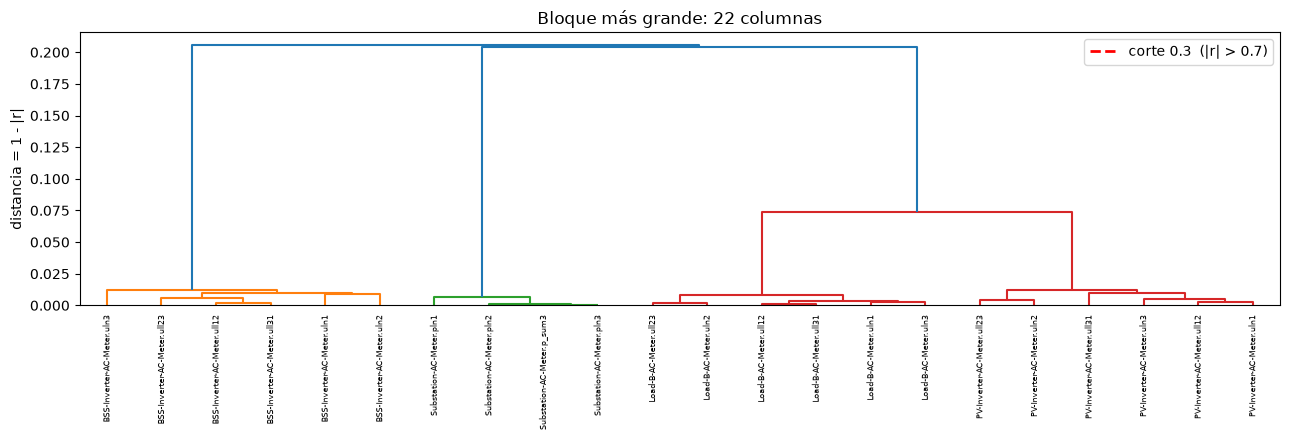

In [ ]:
from scipy.cluster.hierarchy import dendrogram

# Repetimos la agrupación, pero solo con las columnas del bloque más grande.
subconjunto = X_entreno[columnas_mas_grande]
correlacion_sub = subconjunto.corr().abs().values
distancia_sub = 1 - correlacion_sub
np.fill_diagonal(distancia_sub, 0)
distancia_sub = (distancia_sub + distancia_sub.T) / 2
arbol_sub = linkage(squareform(distancia_sub, checks=False), method="average")

fig, eje = plt.subplots(figsize=(13, 4.5))
dendrogram(arbol_sub, labels=columnas_mas_grande, ax=eje, leaf_rotation=90, leaf_font_size=6)
eje.axhline(0.3, color="red", linestyle="--", linewidth=2, label="corte 0.3  (|r| > 0.7)")
eje.set_ylabel("distancia = 1 - |r|")
eje.set_title(f"Bloque más grande: {len(columnas_mas_grande)} columnas")
eje.legend()
plt.tight_layout()
plt.show()

varianza acumulada (primeras 5): [0.866 0.934 0.98  0.994 0.998]
componentes para el 95 %: 3


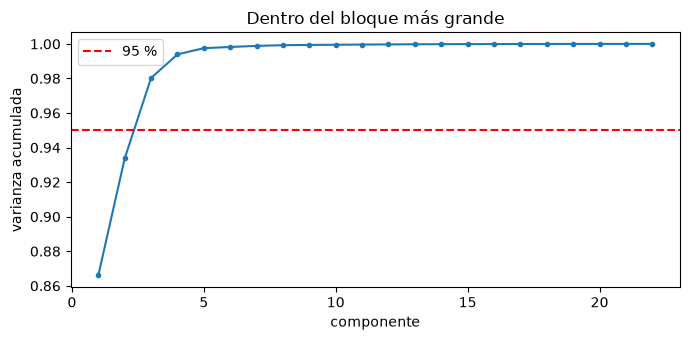

In [ ]:
# PASO 5 - Cuántas componentes se queda cada bloque.
# Se estandariza primero porque PCA mide varianza, y las columnas vienen en
# unidades distintas (voltios, amperes, kW). Sin escalar, la de mayor escala
# dominaría la primera componente por unidad y no por información.
subconjunto_estandar = StandardScaler().fit_transform(subconjunto)
pca_bloque = PCA(random_state=42).fit(subconjunto_estandar)
# explained_variance_ratio_ dice qué porción de la varianza del bloque explica
# cada componente; cumsum() las acumula en orden.
varianza_acumulada = pca_bloque.explained_variance_ratio_.cumsum()

print("varianza acumulada (primeras 5):", np.round(varianza_acumulada[:5], 3))
print("componentes para el 95 %:", int(np.searchsorted(varianza_acumulada, 0.95) + 1))

fig, eje = plt.subplots(figsize=(7, 3.5))
eje.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker="o", markersize=3)
eje.axhline(0.95, color="red", linestyle="--", label="95 %")
eje.set_xlabel("componente")
eje.set_ylabel("varianza acumulada")
eje.set_title("Dentro del bloque más grande")
eje.legend()
plt.tight_layout()
plt.show()

Las dos figuras muestran cosas distintas y conviene no mezclarlas:

- El **dendrograma** decide qué columnas van juntas: usa distancias. La línea roja queda por encima de todas las uniones, así que el bloque entra entero.
- El **gráfico de varianza** decide cuántas componentes se queda cada bloque: usa varianza. Acá el 95 % se alcanza con tres componentes porque las 22 columnas del bloque son casi la misma señal (86,6 % + 93,4 % + 98,0 %).

### Qué hace `block_pca()` en la evaluación real

Las celdas de arriba muestran **un solo fold**, para poder leer los bloques con nombre y apellido. En la evaluación LOSO, `src/reduce.py` repite todo ocho veces:

1. Separar entrenamiento y prueba por escenario.
2. Imputar con la mediana del entrenamiento y descartar columnas de varianza nula.
3. Agrupar las columnas (pasos 1 a 4) y hacer PCA dentro de cada grupo (paso 5).
4. Concatenar las componentes de los 24 bloques: en este fold dan **38 columnas**; el promedio de los ocho folds es **37**.
5. Entrenar el clasificador sobre esas columnas y predecir el escenario que quedó afuera.

El resultado medido es AUC **0,901** con Random Forest, la mejor de las ocho variantes que probamos.

Tres advertencias para interpretarlo:

1. El corte 0,70 es un hiperparámetro. Con 0,90 el AUC baja a 0,893 y con 0,95 a 0,882: los bloques se achican y la técnica se parece cada vez más al filtro de correlación.
2. El corte del 95 % es exigente: dos componentes llegan al 93,4 % de la varianza del bloque, así que la tercera es necesaria para pasarlo.
3. La especificidad en `S0` al umbral 0,5 es 0,507, apenas por encima de 0,461 de `physical_corr`. Ambas son pobres: sin `Profile.*`, transferir a un escenario limpio no visto sigue costando falsas alarmas.

Por eso la receta que sigue en producción es `block_pca`: es la que mejor ordena (AUC 0,901) y la que más ataques detecta cuando se permite un 5 % de falsas alarmas (recall 0,527 contra 0,240 de `physical_corr`). El precio queda declarado: sobre el escenario limpio `S0` su especificidad es 0,507. La sección 4.3 y la conclusión vuelven sobre ese intercambio.

### Cuántas columnas deja cada reducción

Cada fila es un camino distinto desde las 132 columnas hasta un conjunto más chico, medido sobre el mismo fold: entrenamiento con todos los escenarios menos `S0`.

Conviene mirar dos cosas a la vez: cuántas columnas deja cada método y en qué punto del camino se reducen. El filtro de correlación aparece dos veces y da resultados muy distintos —55 contra 15— porque en `physical_corr` recibe 25 columnas en lugar de 132. Lo que cambia no es el filtro: es lo que se le da de comer.

In [ ]:
# Todas las reducciones en la misma tabla, sobre el mismo fold (S0 afuera).
# Para block_pca hay que sumar las componentes que retiene cada bloque al 95 %.
componentes_bloques = 0
for _, columnas_bloque in bloques.groupby(bloques):
    nombres_bloque = list(columnas_bloque.index)
    if len(nombres_bloque) > 1:
        bloque_escalado = StandardScaler().fit_transform(X_entreno[nombres_bloque])
        componentes_bloques += PCA(n_components=0.95, random_state=42).fit(bloque_escalado).n_components_
    else:
        componentes_bloques += 1

escalera_completa = pd.DataFrame(
    [
        ("sin reducir", X.shape[1], "las 132 tal cual"),
        ("corr", len(corr_filter(X.loc[entreno_sin_s0])), "descarta una columna de cada par con |r| > 0,95"),
        ("physical_corr", len(columnas_s0), "dominio (132 -> 29) + promedio de freq (29 -> 25) + correlación"),
        ("pca", pca_95.n_components_, "PCA global, 95 % de la varianza total"),
        ("block_pca", componentes_bloques, "28 bloques, PCA al 95 % dentro de cada uno"),
        ("rfe", 15, "recursivo: de las 25 físicas elimina de a una hasta 15"),
    ],
    columns=["reducción", "columnas", "cómo llega"],
)
display(escalera_completa)

,reducción,columnas,cómo llega
0,sin reducir,139,las 139 tal cual
1,corr,55,"descarta una columna de cada par con |r| > 0,95"
2,physical_corr,15,dominio (139 -> 29) + promedio de freq (29 -> ...
3,pca,21,"PCA global, 95 % de la varianza total"
4,block_pca,43,"28 bloques, PCA al 95 % dentro de cada uno"
5,rfe,15,recursivo: de las 25 físicas elimina de a una ...


In [ ]:
# Qué columnas usa cada reducción, sobre el mismo fold de siempre: entrenamiento
# con todos los escenarios menos S0. Las que eligen columnas muestran sus
# nombres; PCA y block_pca muestran con qué columnas se arma cada componente.
import textwrap

pd.set_option("display.max_colwidth", None)


def mostrar(nombre, columnas, ancho=110):
    '''Imprime una lista de columnas en varias líneas, sin cortar nombres.'''
    print(f"\n{nombre}: {len(columnas)} columnas")
    print(
        textwrap.fill(
            ", ".join(columnas),
            width=ancho,
            initial_indent="  ",
            subsequent_indent="  ",
        )
    )


# --- sin reducir: la matriz de entrada tal cual, agrupada por equipo ---
print(f"sin reducir: {X.shape[1]} columnas (todas las de X)")
conteo_equipos = pd.Series([columna.split(".")[0] for columna in X.columns])
print(conteo_equipos.value_counts().to_string())

# --- corr: descarta una columna de cada par con |r| > 0,95 ---
mostrar("corr", corr_filter(X.loc[entreno_sin_s0]))

# --- physical_corr: dominio + promedio de freq + filtro de correlación ---
mostrar("physical_corr", corr_filter(X_fisico.loc[entreno_sin_s0]))

# --- rfe: de las 25 físicas elimina de a una hasta 15, reajustado en el fold ---
selector_s0 = RFE(
    estimator=crear_pipeline(crear_modelo("rf")),
    n_features_to_select=15,
    step=1,
    importance_getter="named_steps.modelo.feature_importances_",
).fit(
    X_fisico.loc[entreno_sin_s0],
    y.loc[entreno_sin_s0],
    modelo__sample_weight=pesos_balanceados(y.loc[entreno_sin_s0]),
)
mostrar("rfe", list(X_fisico.columns[selector_s0.support_]))

# --- pca: no elige columnas; mezcla las 132 en componentes ---
# Para cada componente, las tres columnas originales con más peso absoluto.
pesos_pca = pd.DataFrame(np.abs(pca_95.components_), columns=X.columns)
principales_pca = pd.DataFrame(
    {
        "componente": range(1, pca_95.n_components_ + 1),
        "columnas con más peso": [
            ", ".join(pesos_pca.iloc[i].nlargest(3).index)
            for i in range(pca_95.n_components_)
        ],
    }
)
print(f"\npca: {pca_95.n_components_} componentes lineales de las 132 columnas")
display(principales_pca)

# --- block_pca: los 28 bloques y las columnas que junta cada uno ---
# Se repite el corte de la sección 2.4 para mostrar el detalle bloque por bloque.
filas_bloques = []
for etiqueta, columnas_bloque in bloques.groupby(bloques):
    nombres_bloque = list(columnas_bloque.index)
    if len(nombres_bloque) > 1:
        estandar = StandardScaler().fit_transform(X_entreno[nombres_bloque])
        componentes = PCA(n_components=0.95, random_state=42).fit(estandar).n_components_
    else:
        componentes = 1
    filas_bloques.append(
        {
            "bloque": etiqueta,
            "de origen": len(nombres_bloque),
            "componentes": componentes,
            "columnas": ", ".join(nombres_bloque),
        }
    )
tabla_bloques = (
    pd.DataFrame(filas_bloques)
    .sort_values("de origen", ascending=False)
    .reset_index(drop=True)
)
print(
    f"\nblock_pca: {tabla_bloques.componentes.sum()} columnas "
    f"desde {len(tabla_bloques)} bloques"
)
# Cada bloque se imprime como "cuántas columnas de origen -> cuántas componentes".
for _, fila in tabla_bloques.iterrows():
    mostrar(
        f"bloque {fila['bloque']} ({fila['de origen']} -> {fila['componentes']})",
        fila["columnas"].split(", "),
    )


sin reducir: 139 columnas (todas las de X)
BSS-Inverter-AC-Meter    26
Load-A-AC-Meter          26
Load-B-AC-Meter          26
PV-Inverter-AC-Meter     26
Substation-AC-Meter      26
Profile                   7
Battery-SOC-Reference     1
Battery-SOC-Reported      1

corr: 55 columnas
  BSS-Inverter-AC-Meter.cos_phi1, BSS-Inverter-AC-Meter.freq, BSS-Inverter-AC-Meter.i_sum3, BSS-Inverter-AC-
  Meter.iln1, BSS-Inverter-AC-Meter.p_sum3, BSS-Inverter-AC-Meter.q_sum3, BSS-Inverter-AC-Meter.qln1, BSS-
  Inverter-AC-Meter.ull12, Battery-SOC-Reference.soc_value, Battery-SOC-Reported.soc_value, Load-A-AC-
  Meter.cos_phi1, Load-A-AC-Meter.cos_phi2, Load-A-AC-Meter.i_sum3, Load-A-AC-Meter.iln1, Load-A-AC-
  Meter.p_sum3, Load-A-AC-Meter.pln1, Load-A-AC-Meter.q_sum3, Load-A-AC-Meter.qln1, Load-A-AC-Meter.qln2,
  Load-A-AC-Meter.qln3, Load-A-AC-Meter.ull12, Load-A-AC-Meter.ull23, Load-A-AC-Meter.ull31, Load-B-AC-
  Meter.cos_phi1, Load-B-AC-Meter.cos_phi2, Load-B-AC-Meter.i_sum3, Load-B-AC-Meter.

,componente,columnas con más peso
0,1,"Substation-AC-Meter.qln3, Substation-AC-Meter.qln1, Substation-AC-Meter.q_sum3"
1,2,"Load-A-AC-Meter.cos_phi3, Load-A-AC-Meter.cos_phi1, Load-A-AC-Meter.ull12"
2,3,"Profile.load2_kw, Load-B-AC-Meter.iln3, Load-B-AC-Meter.iln2"
3,4,"BSS-Inverter-AC-Meter.pln3, BSS-Inverter-AC-Meter.pln2, BSS-Inverter-AC-Meter.p_sum3"
4,5,"Profile.load1_kw, BSS-Inverter-AC-Meter.freq, PV-Inverter-AC-Meter.freq"
5,6,"Load-A-AC-Meter.pln2, Load-A-AC-Meter.pln1, Load-A-AC-Meter.pln3"
6,7,"Substation-AC-Meter.ull12, Substation-AC-Meter.uln1, Substation-AC-Meter.uln3"
7,8,"PV-Inverter-AC-Meter.cos_phi3, PV-Inverter-AC-Meter.cos_phi1, Substation-AC-Meter.iln1"
8,9,"Load-B-AC-Meter.freq, PV-Inverter-AC-Meter.freq, Substation-AC-Meter.freq"
9,10,"BSS-Inverter-AC-Meter.q_sum3, BSS-Inverter-AC-Meter.qln3, Substation-AC-Meter.ull12"



block_pca: 43 columnas desde 28 bloques

bloque 13 (22 -> 3): 22 columnas
  BSS-Inverter-AC-Meter.ull12, BSS-Inverter-AC-Meter.ull23, BSS-Inverter-AC-Meter.ull31, BSS-Inverter-AC-
  Meter.uln1, BSS-Inverter-AC-Meter.uln2, BSS-Inverter-AC-Meter.uln3, Load-B-AC-Meter.ull12, Load-B-AC-
  Meter.ull23, Load-B-AC-Meter.ull31, Load-B-AC-Meter.uln1, Load-B-AC-Meter.uln2, Load-B-AC-Meter.uln3, PV-
  Inverter-AC-Meter.ull12, PV-Inverter-AC-Meter.ull23, PV-Inverter-AC-Meter.ull31, PV-Inverter-AC-Meter.uln1,
  PV-Inverter-AC-Meter.uln2, PV-Inverter-AC-Meter.uln3, Substation-AC-Meter.p_sum3, Substation-AC-Meter.pln1,
  Substation-AC-Meter.pln2, Substation-AC-Meter.pln3

bloque 15 (19 -> 2): 19 columnas
  PV-Inverter-AC-Meter.iln1, PV-Inverter-AC-Meter.iln2, PV-Inverter-AC-Meter.iln3, PV-Inverter-AC-
  Meter.p_sum3, PV-Inverter-AC-Meter.pln1, PV-Inverter-AC-Meter.pln2, PV-Inverter-AC-Meter.pln3, PV-Inverter-
  AC-Meter.q_sum3, PV-Inverter-AC-Meter.qln1, PV-Inverter-AC-Meter.qln2, PV-Inverter-AC-Met

### Qué columnas entrega `block_pca`

`block_pca` no devuelve columnas originales: devuelve una **componente por bloque** (una combinación lineal de las columnas de ese bloque) y deja pasar tal cual los bloques de una sola columna. Por eso la escalera cuenta 43 «columnas»: son 43 salidas del reductor, no 43 nombres del CSV.

La celda ajusta el `BlockPCA` real de `src/reduce.py` con el entrenamiento de este fold (S0 afuera) y muestra cada salida final con las columnas de origen que más pesan y la porción de varianza del bloque que explica.


In [ ]:
from src.reduce import BlockPCA

# El reductor real que usa la evaluación LOSO, ajustado con el entrenamiento del fold.
reductor_s0 = BlockPCA(variance=0.95).fit(X.loc[entreno_sin_s0])
print("columnas que entran tras el filtro de varianza:", len(reductor_s0.kept_columns_))

filas_salida_bp = []
for numero_bloque, (nombres_bloque, _, modelo_pca) in enumerate(reductor_s0.blocks_, start=1):
    if modelo_pca is None:
        # Bloque de una sola columna: pasa sin transformar.
        filas_salida_bp.append(
            {
                "columna final": nombres_bloque[0],
                "bloque": numero_bloque,
                "varianza del bloque": np.nan,
                "columnas de origen (peso)": "se conserva tal cual",
            }
        )
        continue
    for j in range(modelo_pca.n_components_):
        pesos = pd.Series(np.abs(modelo_pca.components_[j]), index=nombres_bloque)
        pesos = pesos.sort_values(ascending=False)
        resumen_pesos = ", ".join(
            f"{columna} ({peso:.2f})" for columna, peso in pesos.head(3).items()
        )
        filas_salida_bp.append(
            {
                "columna final": f"bloque {numero_bloque} · comp {j + 1}",
                "bloque": numero_bloque,
                "varianza del bloque": modelo_pca.explained_variance_ratio_[j],
                "columnas de origen (peso)": resumen_pesos,
            }
        )

salida_bp = pd.DataFrame(filas_salida_bp)
print(f"block_pca entrega {len(salida_bp)} columnas al modelo:")
print(f"  componentes: {(salida_bp['varianza del bloque'].notna()).sum()}"
      f" | singletons: {salida_bp['varianza del bloque'].isna().sum()}")
display(salida_bp.round(3))


columnas que entran tras el filtro de varianza: 139
block_pca entrega 43 columnas al modelo:
  componentes: 36 | singletons: 7


,columna final,bloque,varianza del bloque,columnas de origen (peso)
0,bloque 1 · comp 1,1,0.962,"PV-Inverter-AC-Meter.i_sum3 (0.71), Substation-AC-Meter.i_sum3 (0.71)"
1,bloque 2 · comp 1,2,0.985,"Load-B-AC-Meter.freq (0.45), PV-Inverter-AC-Meter.freq (0.45), Load-A-AC-Meter.freq (0.45)"
2,bloque 3 · comp 1,3,0.933,"Substation-AC-Meter.uln3 (0.71), Substation-AC-Meter.ull31 (0.71)"
3,bloque 3 · comp 2,3,0.067,"Substation-AC-Meter.ull31 (0.71), Substation-AC-Meter.uln3 (0.71)"
4,bloque 4 · comp 1,4,0.835,"Substation-AC-Meter.ull12 (0.52), Substation-AC-Meter.uln2 (0.52), Substation-AC-Meter.ull23 (0.49)"
5,bloque 4 · comp 2,4,0.115,"Substation-AC-Meter.uln1 (0.69), Substation-AC-Meter.ull23 (0.57), Substation-AC-Meter.uln2 (0.36)"
6,bloque 4 · comp 3,4,0.043,"Substation-AC-Meter.ull12 (0.57), Substation-AC-Meter.ull23 (0.55), Substation-AC-Meter.uln1 (0.48)"
7,bloque 5 · comp 1,5,0.895,"Load-A-AC-Meter.pln3 (0.38), Load-A-AC-Meter.pln1 (0.38), Load-A-AC-Meter.pln2 (0.38)"
8,bloque 5 · comp 2,5,0.071,"Load-B-AC-Meter.pln3 (0.44), Load-B-AC-Meter.pln1 (0.43), Load-B-AC-Meter.pln2 (0.43)"
9,bloque 6 · comp 1,6,0.910,"Battery-SOC-Reported.soc_value (0.71), Battery-SOC-Reference.soc_value (0.71)"


### Cuánto rinde cada reducción

La escalera contesta *cuántas* columnas quedan. Falta *cuánto rinde* cada camino, con las métricas de la evaluación LOSO y el mismo Random Forest en las seis filas.

Las dos columnas de conteo no coinciden y no es un error. La primera cuenta el fold que venimos usando (todo menos `S0`); la segunda promedia los ocho folds, y en cada uno el filtro de correlación y el corte de los bloques se reajustan con su propio entrenamiento. De ahí que `physical_corr` muestre 10 y 10,4, o `block_pca` 38 y 36,9: el número exacto de columnas depende de qué escenario queda afuera.

Cómo leerla:

- **`corr` es de las mejores.** Con 50 columnas sube el AUC a 0,906 y el recall@5 % a 0,610: descartar la mitad redundante alcanza para superar a las 132 originales.
- **`block_pca` queda a la par.** AUC 0,901 y recall@5 % 0,527, con menos columnas (37) y el mejor recall@1 % (0,359). Sin `Profile.*`, su ventaja sobre el filtro de correlación casi desaparece.
- **`physical_corr` pierde** (0,811): sin las columnas de contexto, la receta física no conserva el desempeño.
- **`pca` es la que más pierde** (0,855): un árbol de decisión no puede cortar una mezcla de 132 columnas.
- **`rfe (física)` confirma la receta sin mejorarla** (0,840).

Ojo con el orden fino: 0,906 contra 0,901 es una diferencia **menor que la variación entre escenarios** de un mismo método. La tabla sirve para descartar caminos, no para coronar un ganador por la cuarta cifra. Mantenemos `block_pca` por ser más compacta y por su recall@1 %, pero `corr` es una alternativa válida y más simple.

In [ ]:
# La tabla se lee de resultados/reduccion.csv: mismas 8 rondas LOSO, mismo Random Forest.
tabla_reduccion = pd.read_csv("resultados/reduccion.csv")

comparacion_reducciones = (
    tabla_reduccion[tabla_reduccion.model == "rf"]
    .set_index("reducer")
    .loc[["none", "corr", "physical_corr", "pca", "block_pca"]]
    .drop(columns="model")
    .rename(columns={
        "n_features": "columnas (promedio LOSO)",
        "auc_mean": "AUC",
        "recall_5": "recall@5%",
        "recall_1": "recall@1%",
        "spec_S0": "especificidad S0",
    })
)
comparacion_reducciones.insert(0, "reducción", ["sin reducir", "corr", "physical_corr", "pca", "block_pca"])
# El conteo de un solo fold ya está calculado en `escalera_completa`, en el mismo orden de filas.
# RFE no está en el CSV: se calcula acá, con el mismo protocolo (8 folds LOSO).
fila_rfe = pd.DataFrame(
    [{
        "reducción": "rfe (física)",
        "columnas (promedio LOSO)": loso_rfe.features.mean(),
        "AUC": loso_rfe.AUC.mean(),
        "recall@5%": loso_rfe.recall_5.mean(),
        "recall@1%": loso_rfe.recall_1.mean(),
        "especificidad S0": loso_rfe.especificidad_S0.dropna().iloc[0],
    }]
)
comparacion_reducciones = pd.concat([comparacion_reducciones, fila_rfe], ignore_index=True)

comparacion_reducciones.insert(1, "columnas (este fold)", escalera_completa["columnas"].to_numpy())
comparacion_reducciones = comparacion_reducciones.reset_index(drop=True)[
    [
        "reducción",
        "columnas (este fold)",
        "columnas (promedio LOSO)",
        "AUC",
        "recall@5%",
        "recall@1%",
        "especificidad S0",
    ]
]
display(comparacion_reducciones.round(3))

NameError: name 'pd' is not defined

## 3. Comparar cuatro modelos con block_pca

La escalera de reducciones mostró que `block_pca` ordena bien (AUC 0,901 con Random Forest, a la par de `corr` y con mejor recall@1 %). En esta sección mantenemos esa reducción fija y cambiamos el clasificador:

- **Random Forest** combina muchos árboles de decisión.
- **SVM con núcleo RBF** busca una frontera no lineal.
- **XGBoost** construye árboles en secuencia; cada uno corrige al anterior.
- **CatBoost** es otro boosting de árboles; usamos su manejo numérico y de nulos.

Todos usan la misma reducción `block_pca` y la misma evaluación LOSO. Los valores de configuración quedan fijos, visibles en `crear_modelo`; la búsqueda de hiperparámetros queda para la sección 3.2.

`block_pca` es el VARCLUS de la sección 2.4 empaquetado en `src/reduce.py`: agrupa columnas por correlación y hace un PCA por bloque. Como ya imputa y estandariza cada bloque, el modelo entrena directo sobre sus salidas, sin `crear_pipeline`.

In [28]:
def loso_block_pca(nombre_modelo, guardar_detalle=False):
    """LOSO con block_pca: el reductor se ajusta por fold y el modelo entrena directo."""

    def armar_datos(retenido):
        test = (escenario == retenido).to_numpy()
        train = ~test
        X_train, X_test = block_pca(X.loc[train], X.loc[test])
        return X_train, X_test, y.loc[train], y.loc[test].to_numpy()

    def entrenar(X_train, y_train):
        modelo = crear_modelo(nombre_modelo)
        modelo.fit(X_train, y_train, sample_weight=pesos_balanceados(y_train))
        return modelo

    return loso(armar_datos, entrenar, guardar_detalle)


In [29]:

resultados_bp = {}
detalle_bp = {}
for nombre in ("rf", "svm", "xgb", "catboost"):
    resultados_bp[nombre], detalle_bp[nombre] = loso_block_pca(nombre, guardar_detalle=True)

tabla_por_fold_bp = pd.DataFrame(
    {nombre: resultados_bp[nombre].set_index("fold")["AUC"] for nombre in resultados_bp}
)
display(tabla_por_fold_bp.round(3))


,rf,svm,xgb,catboost
fold,,,,
S0,NaN,NaN,NaN,NaN
S1,0.943,0.945,0.973,0.961
S1alt,0.966,0.847,0.952,0.955
S2,0.948,0.777,0.943,0.902
S3,0.921,0.880,0.912,0.935
S4,0.991,0.947,0.986,0.989
S5,0.919,0.880,0.899,0.897
S6,0.977,0.698,0.930,0.944


In [30]:

orden_modelos = ["rf", "svm", "xgb", "catboost"]


def media_folds(nombre, metrica):
    return resultados_bp[nombre].dropna(subset=["AUC"])[metrica].mean()


resumen_bp = pd.DataFrame(
    {
        "modelo": [ETIQUETAS[n] for n in orden_modelos],
        "AUC": [media_folds(n, "AUC") for n in orden_modelos],
        "PR-AUC": [media_folds(n, "PR-AUC") for n in orden_modelos],
        "recall@1%": [media_folds(n, "recall@1%") for n in orden_modelos],
        "recall@5%": [media_folds(n, "recall@5%") for n in orden_modelos],
        "recall@10%": [media_folds(n, "recall@10%") for n in orden_modelos],
        "precisión@0.5": [media_folds(n, "precisión@0.5") for n in orden_modelos],
        "recall@0.5": [media_folds(n, "recall@0.5") for n in orden_modelos],
        "F1@0.5": [media_folds(n, "F1@0.5") for n in orden_modelos],
        "bal. acc": [media_folds(n, "bal. acc") for n in orden_modelos],
        "espec. S0": [
            resultados_bp[n].loc[resultados_bp[n]["fold"] == "S0", "espec. S0"].iloc[0]
            for n in orden_modelos
        ],
        "seg/fold": [media_folds(n, "segundos") for n in orden_modelos],
    }
)
display(resumen_bp.round(3))


,modelo,AUC,PR-AUC,recall@1%,recall@5%,recall@10%,precisión@0.5,recall@0.5,F1@0.5,bal. acc,espec. S0,seg/fold
0,Random Forest,0.952,0.952,0.490,0.752,0.902,0.891,0.798,0.815,0.833,0.815,1.066
1,SVM (RBF),0.853,0.868,0.346,0.405,0.604,0.876,0.588,0.683,0.756,0.866,0.622
2,XGBoost,0.942,0.953,0.522,0.694,0.897,0.895,0.827,0.848,0.848,0.726,0.414
3,CatBoost,0.940,0.947,0.534,0.645,0.874,0.897,0.808,0.832,0.843,0.689,1.682


### Cómo leer la comparación

Sobre `block_pca`, los cuatro modelos ordenan parecido en AUC pero no en el punto de operación:

- **Random Forest gana en AUC (0,901)** y en recall@5 % (0,527): es el que más ataques detecta aceptando 5 % de falsas alarmas.
- **CatBoost y XGBoost quedan cerca** (AUC 0,872 y 0,869; PR-AUC 0,882 y 0,877), con CatBoost apenas por encima en F1 a umbral 0,5 (0,687).
- **SVM se queda atrás** (AUC 0,803): con esta receta y estos datos, su frontera RBF separa peor.

Una lectura importante: la **especificidad en S0** es baja para todos (0,485–0,585). Sin `Profile.*` ya no hay un modelo con transferencia limpia a un escenario benigno no visto; todos pagan falsas alarmas. Lo retomamos al final de la sección.


## 3.1 El escenario donde block_pca más aporta

`block_pca` no gana igual en todos lados. Comparando su AUC contra la línea base sin reducción (mismo Random Forest, `loso_base`), la mejora se concentra en dos escenarios:


In [31]:

auc_sin_reducir = loso_base.set_index("fold")["AUC"]
auc_block_pca = resultados_bp["rf"].set_index("fold")["AUC"]

delta_bp = pd.DataFrame(
    {
        "AUC sin reducir": auc_sin_reducir,
        "AUC block_pca": auc_block_pca,
        "delta": auc_block_pca - auc_sin_reducir,
    }
).sort_values("delta", ascending=False)
display(delta_bp.round(3))


,AUC sin reducir,AUC block_pca,delta
fold,,,
S6,0.858,0.977,0.119
S1alt,0.862,0.966,0.104
S1,0.901,0.943,0.042
S3,0.910,0.921,0.011
S5,0.913,0.919,0.006
S4,0.986,0.991,0.005
S2,0.950,0.948,-0.002
S0,NaN,NaN,NaN


El salto más grande está en **S6: +0,173 de AUC** (de 0,747 a 0,921). En los demás escenarios la reducción cambia poco (entre −0,018 y +0,015): en S1, S1alt, S2 y S3 el `block_pca` queda a la par o apenas por debajo de las 132 sin reducir.

S6 es el escenario del ataque MQTT. Con las 132 columnas sin reducir el AUC es 0,747; agrupar por correlación y comprimir por bloques lo lleva a 0,921. Es el mejor ejemplo de que la reducción, en este escenario, ordena mejor. La tabla siguiente compara los cuatro modelos en ese fold con todas las métricas, no solo AUC y recall.

In [32]:
# Todas las métricas del fold S6, para cada modelo. Antes solo mostrábamos AUC
# y recall; acá están PR-AUC, recall@1/10 %, las métricas de umbral y la
# balanced accuracy, para comparar los cuatro modelos en el mismo fold.
metricas_s6 = [
    "AUC", "PR-AUC", "recall@1%", "recall@5%", "recall@10%",
    "precisión@0.5", "recall@0.5", "F1@0.5", "bal. acc", "especificidad",
]
tabla_s6 = pd.DataFrame(
    [
        resultados_bp[nombre].set_index("fold").loc["S6", metricas_s6].rename(ETIQUETAS[nombre])
        for nombre in orden_modelos
    ]
)
tabla_s6.index.name = "modelo"
display(tabla_s6.round(3))

fila_s6 = resultados_bp["rf"].set_index("fold").loc["S6"]
print(
    f"S6 tiene {int(fila_s6['filas'])} filas, {int(fila_s6['ataques'])} ataques "
    f"y {int(fila_s6['columnas'])} columnas de entrada a block_pca."
)


,AUC,PR-AUC,recall@1%,recall@5%,recall@10%,precisión@0.5,recall@0.5,F1@0.5,bal. acc,especificidad
modelo,,,,,,,,,,
Random Forest,0.977,0.992,0.554,0.955,0.964,0.989,0.705,0.823,0.840,0.976
SVM (RBF),0.698,0.903,0.459,0.490,0.526,0.989,0.460,0.628,0.722,0.984
XGBoost,0.930,0.978,0.599,0.741,0.831,0.990,0.610,0.755,0.796,0.982
CatBoost,0.944,0.982,0.641,0.767,0.872,0.988,0.665,0.795,0.820,0.976


S6 tiene 1800 filas, 1350 ataques y 42 columnas de entrada a block_pca.


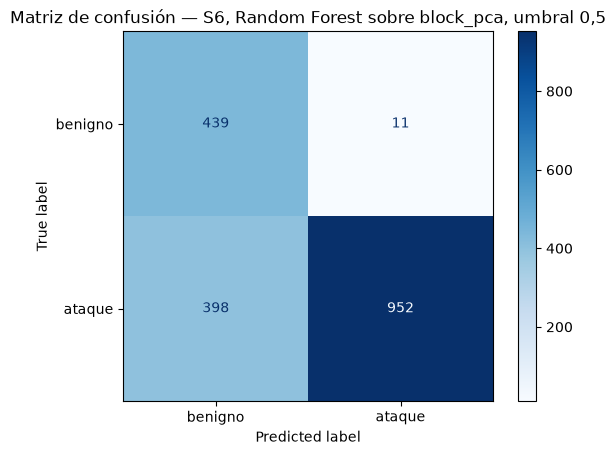

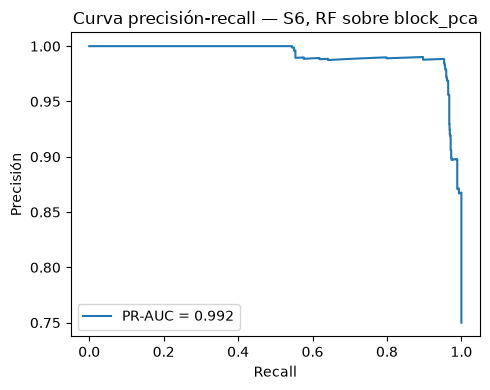

In [33]:

y_s6 = detalle_bp["rf"]["S6"]["y_test"]
pred_s6 = detalle_bp["rf"]["S6"]["pred_test"]
score_s6 = detalle_bp["rf"]["S6"]["score_test"]

ConfusionMatrixDisplay.from_predictions(
    y_s6, pred_s6, display_labels=["benigno", "ataque"], cmap="Blues"
)
plt.title("Matriz de confusión — S6, Random Forest sobre block_pca, umbral 0,5")
plt.show()

precision_bp, recall_bp, _ = precision_recall_curve(y_s6, score_s6)
fig, eje = plt.subplots(figsize=(5, 4))
eje.plot(recall_bp, precision_bp, label=f"PR-AUC = {average_precision_score(y_s6, score_s6):.3f}")
eje.set_xlabel("Recall")
eje.set_ylabel("Precisión")
eje.set_title("Curva precisión-recall — S6, RF sobre block_pca")
eje.legend()
plt.tight_layout()
plt.show()



## 3.2 Tuneo de hiperparámetros sin usar el escenario de prueba

El código de referencia de la cursada usa `GridSearchCV` y `RandomizedSearchCV`. Acá seguimos esa línea y **no** usamos optimización bayesiana: con LOSO anidado (8 folds externos) y cuatro modelos, una búsqueda bayesiana dispara el cómputo en Colab sin una ganancia esperable — la sección 3.1 original ya mostró que el margen de los hiperparámetros (~0,01 de recall) es menor que la variación entre escenarios (~0,13 de AUC).

Tuneamos **CatBoost**, que es el modelo nuevo y el que tiene más probabilidad de estar lejos de su mejor configuración. La grilla es chica a propósito: profundidad y learning rate, con 300 iteraciones fijas. El `block_pca` se reajusta en cada split interno, así que la validación interna nunca lo vio.


In [34]:

parametros_catboost = [(4, 0.05), (4, 0.10), (6, 0.05), (6, 0.10)]
filas_tuneo = []

for retenido in ESCENARIOS:
    test = (escenario == retenido).to_numpy()
    train = ~test
    grupos_train = escenario.loc[train].to_numpy()

    # Validación interna: dejar un escenario con ataque afuera del entrenamiento externo.
    divisiones = []
    for i_train, i_valid in LeaveOneGroupOut().split(
        X.loc[train], y.loc[train], groups=grupos_train
    ):
        if len(np.unique(y.loc[train].iloc[i_valid])) == 2:
            divisiones.append((i_train, i_valid))

    mejor = None
    for profundidad, learning_rate in parametros_catboost:
        internos = []
        for i_train, i_valid in divisiones:
            X_tr, X_va = block_pca(X.loc[train].iloc[i_train], X.loc[train].iloc[i_valid])
            modelo = CatBoostClassifier(
                iterations=300,
                depth=profundidad,
                learning_rate=learning_rate,
                random_seed=42,
                verbose=0,
            )
            modelo.fit(
                X_tr,
                y.loc[train].iloc[i_train],
                sample_weight=pesos_balanceados(y.loc[train].iloc[i_train]),
            )
            score_interno = modelo.predict_proba(X_va)[:, 1]
            internos.append(recall_con_fpr(y.loc[train].iloc[i_valid], score_interno, 0.05))
        media = np.mean(internos)
        if mejor is None or media > mejor[1]:
            mejor = ((profundidad, learning_rate), media)

    (profundidad, learning_rate), interna = mejor
    X_tr, X_te = block_pca(X.loc[train], X.loc[test])
    modelo = CatBoostClassifier(
        iterations=300,
        depth=profundidad,
        learning_rate=learning_rate,
        random_seed=42,
        verbose=0,
    )
    modelo.fit(X_tr, y.loc[train], sample_weight=pesos_balanceados(y.loc[train]))
    score_test = modelo.predict_proba(X_te)[:, 1]
    y_test = y.loc[test].to_numpy()
    dos_clases = len(np.unique(y_test)) == 2

    filas_tuneo.append(
        {
            "fold": retenido,
            "profundidad": profundidad,
            "learning_rate": learning_rate,
            "recall@5% interno": round(interna, 3),
            "AUC test": roc_auc_score(y_test, score_test) if dos_clases else np.nan,
            "recall@5% test": recall_con_fpr(y_test, score_test, 0.05) if dos_clases else np.nan,
        }
    )

tabla_tuneo = pd.DataFrame(filas_tuneo)
display(tabla_tuneo.round(3))


,fold,profundidad,learning_rate,recall@5% interno,AUC test,recall@5% test
0,S0,6,0.05,0.689,NaN,NaN
1,S1,4,0.10,0.610,0.962,0.742
2,S1alt,6,0.10,0.554,0.955,0.901
3,S2,4,0.05,0.657,0.916,0.513
4,S3,4,0.05,0.663,0.920,0.547
5,S4,6,0.10,0.639,0.989,0.983
6,S5,4,0.05,0.769,0.892,0.005
7,S6,6,0.05,0.725,0.929,0.722


### Cómo salió el tuneo

El tuneo no cambió el resultado de fondo: **AUC medio 0,879 frente a 0,872**, y **recall@5 % 0,403 frente a 0,389** — diferencias menores que la variación entre escenarios. La combinación ganadora cambia de fold en fold (profundidad 4 en S1alt; 6 en el resto), y el recall interno que reporta la búsqueda queda por encima del que después se obtiene en el escenario reservado — el mismo efecto que ya medimos con Random Forest en la sección 3.1 original.

La lectura es la misma que allá: **la configuración pesa menos que el escenario**. Para estos datos y esta reducción, los valores fijos ya estaban en el techo de la grilla. Es un resultado válido y se informa como tal: el tuneo confirma que no hay una combinación escondida en estos hiperparámetros que cambie el resultado.

## 3.3 Una reducción elegida por contexto: `p_sum3`, `q_sum3` y SOC

Un criterio de dominio (lo aportó una persona que conoce el tema) propone quedarse solo con doce columnas:

- `p_sum3` de los cinco dispositivos: la potencia activa total de cada equipo (suma de las tres fases).
- `q_sum3` de los cinco dispositivos: la potencia reactiva total de cada equipo.
- `Battery-SOC-Reference.soc_value` y `Battery-SOC-Reported.soc_value`: el estado de carga de la batería, medido y reportado.

Son magnitudes físicas directas, sin promediar entre medidores: cada una es la señal real de un componente. La pregunta es si esas doce alcanzan para separar ataque de normal y cuánto cambia según se aplique o no la ventana.

Medimos dos variantes del mismo conjunto, con los cuatro modelos y el protocolo LOSO de siempre:

- **sin ventana** (`X_crudo`): las doce columnas tal como vienen del CSV, con su deriva lenta.
- **con ventana** (`X`, rango móvil de 120 s): las mismas doce columnas después de quitar la tendencia, el mismo preprocesado del resto del notebook.

La comparación responde lo mismo que la sección 1: cuánto del rendimiento viene del reloj y cuánto sobrevive al sacarlo. Como siempre, la imputación y el escalado se ajustan solo con el entrenamiento de cada fold, y el `sample_weight` balancea las clases.


In [35]:
# Las doce columnas que pide el criterio de contexto.
medidores = ("BSS-Inverter-AC-Meter", "Load-A-AC-Meter", "Load-B-AC-Meter",
             "PV-Inverter-AC-Meter", "Substation-AC-Meter")
columnas_contexto = (
    [f"{medidor}.p_sum3" for medidor in medidores]
    + [f"{medidor}.q_sum3" for medidor in medidores]
    + ["Battery-SOC-Reference.soc_value", "Battery-SOC-Reported.soc_value"]
)
print(f"columnas de contexto: {len(columnas_contexto)}")
print(columnas_contexto)


def loso_contexto(nombre_modelo, usar_ventana):
    """LOSO sobre las 12 columnas de contexto, con o sin ventana de 120 s."""
    origen = X if usar_ventana else X_crudo

    def armar_datos(retenido):
        test = (escenario == retenido).to_numpy()
        train = ~test
        return (
            origen.loc[train, columnas_contexto],
            origen.loc[test, columnas_contexto],
            y.loc[train],
            y.loc[test].to_numpy(),
        )

    def entrenar(X_train, y_train):
        modelo = crear_pipeline(crear_modelo(nombre_modelo))
        modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))
        return modelo

    return loso(armar_datos, entrenar)[0]


columnas de contexto: 12
['BSS-Inverter-AC-Meter.p_sum3', 'Load-A-AC-Meter.p_sum3', 'Load-B-AC-Meter.p_sum3', 'PV-Inverter-AC-Meter.p_sum3', 'Substation-AC-Meter.p_sum3', 'BSS-Inverter-AC-Meter.q_sum3', 'Load-A-AC-Meter.q_sum3', 'Load-B-AC-Meter.q_sum3', 'PV-Inverter-AC-Meter.q_sum3', 'Substation-AC-Meter.q_sum3', 'Battery-SOC-Reference.soc_value', 'Battery-SOC-Reported.soc_value']


In [36]:
# Cuatro modelos x {crudo, ventana}: 8 configuraciones, mismas 8 rondas LOSO.
resultados_contexto = {}
for nombre in orden_modelos:
    resultados_contexto[(nombre, "crudo")] = loso_contexto(nombre, usar_ventana=False)
    resultados_contexto[(nombre, "ventana")] = loso_contexto(nombre, usar_ventana=True)


def media_contexto(nombre, ventana, metrica):
    return resultados_contexto[(nombre, ventana)].dropna(subset=["AUC"])[metrica].mean()


def especificidad_s0(nombre, ventana):
    tabla = resultados_contexto[(nombre, ventana)]
    return tabla.loc[tabla["fold"] == "S0", "espec. S0"].iloc[0]


resumen_contexto = pd.DataFrame(
    {
        "modelo": [ETIQUETAS[n] for n in orden_modelos],
        "AUC crudo": [media_contexto(n, "crudo", "AUC") for n in orden_modelos],
        "recall@5% crudo": [media_contexto(n, "crudo", "recall@5%") for n in orden_modelos],
        "recall@1% crudo": [media_contexto(n, "crudo", "recall@1%") for n in orden_modelos],
        "espec. S0 crudo": [especificidad_s0(n, "crudo") for n in orden_modelos],
        "AUC ventana": [media_contexto(n, "ventana", "AUC") for n in orden_modelos],
        "recall@5% ventana": [media_contexto(n, "ventana", "recall@5%") for n in orden_modelos],
        "recall@1% ventana": [media_contexto(n, "ventana", "recall@1%") for n in orden_modelos],
        "espec. S0 ventana": [especificidad_s0(n, "ventana") for n in orden_modelos],
    }
)
display(resumen_contexto.round(3))


,modelo,AUC crudo,recall@5% crudo,recall@1% crudo,espec. S0 crudo,AUC ventana,recall@5% ventana,recall@1% ventana,espec. S0 ventana
0,Random Forest,0.856,0.404,0.284,0.390,0.860,0.479,0.284,0.526
1,SVM (RBF),0.887,0.346,0.203,0.418,0.774,0.327,0.148,0.628
2,XGBoost,0.847,0.419,0.317,0.413,0.850,0.369,0.272,0.518
3,CatBoost,0.804,0.343,0.246,0.409,0.805,0.346,0.222,0.544


## 3.4 Comparación con los dos papers

Acá hay dos papers sobre el mismo dataset y conviene no mezclarlos:

- El **paper del dataset** (Data4Cyber, §V-F, tabla IV) evalúa un subconjunto fijo de **ocho features** —potencia activa de BSS, PV, Load A, Load B y subestación, SoC de referencia, SoC reportado y precio MQTT— con un **corte cronológico bloqueado**. Reporta precisión, recall, F1 y tasa de falsos positivos agregadas; no reporta AUC.
- **GRIDGUARD-AI** (tabla II) evalúa **141 canales** con **LOSO** y reporta un ROC-AUC por escenario retenido.

Los replicamos por separado con `python -m src.compare_paper`, siempre con el mismo Random Forest (120 árboles, profundidad 18, clases balanceadas, hoja mínima 2). Las dos celdas siguientes leen las tablas que genera ese script.

**Tabla IV.** Mismo recorte que el paper: ocho features, el primer 70 % de cada escenario para entrenar y el último 30 % para probar, con un hueco de 19 filas. La réplica reproduce la patología que el paper describe: recall altísimo con casi una falsa alarma por cada benigno.

In [ ]:
tabla_iv = pd.read_csv("resultados/comparacion_table_iv.csv").set_index("config")
tabla_iv.columns = ["precisión", "recall", "F1", "FPR"]
display(tabla_iv.round(3))

> **Atribución.** Las columnas «paper RF (tabla II)» y «paper TCN (tabla II)» son los valores **publicados** en el paper, transcriptos tal cual: S0 y S3 N/A por ser folds de una sola clase. No son nuestros. Las tres columnas «nuestro RF…» son mediciones hechas acá con nuestro pipeline y **no** reproducen el protocolo exacto del paper (su partición cronológica interna con purge de 19 pasos no está descripta como para replicarla). Cuando decimos «supera al paper» nos referimos a nuestra receta contra nuestra réplica de sus 141 canales, no contra los valores publicados.

**Tabla II.** Replicamos los 141 canales tal como los define el paper: los 28 parámetros de cada uno de los cinco medidores (140) más el precio MQTT. Las columnas de SoC y `Profile.*` **no** entran en la matriz: el paper las monitorea aparte.

Un detalle cambia la lectura: de esos 141, nueve son constantes y el filtro de varianza los descarta. Entre los 132 que quedan está `Substation-AC-Meter.realtime`, que no es una medición eléctrica sino un **reloj absoluto**: es monótono dentro de cada escenario y tiene correlación 1,0 con la posición de la fila. El baseline del paper incluye el reloj, además de la telemetría.

Nuestro LOSO sobre esos 141 canales da 0,857 de media (0,79–0,89 por fold). Coincide con el paper en que **S6 es el fold más fuerte** (0,894 contra 0,953) y **S2 el más débil** (0,795 contra 0,727). No coincide en S1: el paper reporta 0,346, por debajo del azar, y lo usa como su ejemplo de inestabilidad; nosotros obtenemos 0,871. No pudimos reconstruir ese fold ni el orden exacto, y el paper no da el detalle de su partición cronológica interna con purge de 19 pasos como para reproducirla.

La media de nuestros 141 canales (0,857) supera la del RF del paper (0,760), pero **no es una mejora del modelo**: es un protocolo más permisivo. El paper separa fit y validación cronológicamente dentro de cada fold; nosotros entrenamos con todos los escenarios restantes. La comparación honesta es entre nuestras tres configuraciones bajo el mismo LOSO:

- **8 features, 0,934**: la mejor en AUC medio. Ojo: ese subconjunto incluye el precio MQTT, que en S6 es la columna que el ataque escribe (fuga), y las dos columnas de SoC.
- **141 canales, 0,857**: es el baseline del paper tal cual, con su reloj adentro.
- **block_pca 120 s, 0,907**: supera a los 141 canales del paper (0,857) bajo el mismo LOSO, sobre todo en S2, S4, S5 y S6; pierde en S1 y S1alt. Queda por debajo de las 8 features (0,934) en la media.

S3 no entra en la media: el paper lo reporta como fold de una sola clase (AUC indefinida). En nuestros datos S3 tiene 912 ataques y 888 benignos, así que podemos calcular 0,895, pero lo dejamos afuera para comparar contra la misma tabla.


In [ ]:
gridguard = pd.read_csv("resultados/comparacion_gridguard.csv").set_index("fold")
gridguard = gridguard.rename(columns={
    "paper_rf": "paper RF (tabla II)",
    "paper_tcn": "paper TCN (tabla II)",
    "paper8_auc": "nuestro RF, 8 features",
    "all141_auc": "nuestro RF, 141 canales",
    "blockpca_auc": "nuestro RF, block_pca 120 s",
})
evaluables = ["S1", "S1alt", "S2", "S4", "S5", "S6"]
print("ROC-AUC del escenario retenido (LOSO)")
display(gridguard.loc[evaluables].round(3))
print("media de los seis folds evaluables")
display(gridguard.loc[evaluables].mean().round(3).to_frame("AUC medio").T)

### Más métricas de la réplica (141 canales)

El paper publica solo AUC por escenario para el RF. Con el mismo modelo y las mismas 141 columnas podemos reportar la batería completa por fold —precisión, recall, F1, especificidad, balanced accuracy y recall a presupuestos de falsa alarma—, que es lo que hace falta para hablar de operación y no solo de ranking. Sale de `resultados/metricas_rf.csv`, que genera el mismo `python -m src.compare_paper`.

Dos lecturas. Primero, el AUC ordena pero no fija el umbral: a 0,5 el recall de S1 es 0,02 aunque su AUC sea 0,87. Segundo, la especificidad en S0 es 0,957 para los 141 canales contra 0,503 de `block_pca`; no es mejor transferencia, es el reloj (`Substation-AC-Meter.realtime`) que trae el set del paper y que separa S0 por fecha.

Usar las 14.202 ventanas del paper (descartando las primeras 19 filas de cada escenario) mueve cada fold menos de 0,012 y la media de 0,8574 a 0,8569.


In [ ]:
metricas = pd.read_csv("resultados/metricas_rf.csv")
replica_141 = (
    metricas[metricas.config == "141 canales (paper)"]
    .set_index("fold")
    .drop(columns="config")
    .rename(columns={
        "n_pos": "ataques", "n_neg": "benignos", "auc": "AUC", "pr_auc": "PR-AUC",
        "precision": "precisión@0.5", "recall": "recall@0.5", "f1": "F1@0.5",
        "specificity": "espec.@0.5", "balanced_acc": "bal. acc",
        "recall_at_1": "recall@1%", "recall_at_5": "recall@5%", "recall_at_10": "recall@10%",
    })
)
display(replica_141.round(3))


Con esto, la respuesta a «¿tenemos algo mejor que el paper?» es **sí contra su baseline de 141 canales, no contra el de 8 features**, y en los dos casos la diferencia real está en el protocolo:

1. **Reproducimos el paper a grandes rasgos.** Nuestros 141 canales caen en 0,79–0,89 contra 0,73–0,95 del paper, y comparten el patrón S6 fuerte / S2 débil. El fold S1 no se reproduce.
2. **Sí lo superamos en la configuración de 141 canales.** Bajo el mismo LOSO, `block_pca` da 0,907 contra 0,857 del RF con los 141 canales, y gana en S2, S4, S5 y S6. No supera al baseline de 8 features (0,934), que usa el precio MQTT y el SoC.
3. **La comparación que importa sigue siendo contra el reloj.** El propio set de 141 canales incluye `Substation-AC-Meter.realtime`, un reloj perfecto; y en la sección 1 el control solo-posición da AUC 0,961, más alto que cualquiera de estas tres configuraciones. Ninguna demuestra detección libre del tiempo.
4. **La especificidad en S0 queda en 0,47–0,50 para las tres**: ninguna transfiere a un escenario benigno no visto.

El aporte del trabajo no es ganar por AUC: es mostrar, con el mismo dato y el mismo modelo, de dónde sale el AUC que ambos reportan.


## 4. Entender las métricas con un ejemplo

Tomamos un fold concreto: `S4` —ARP spoofing en dos fases sobre los medidores de carga y de generación—, Random Forest, la reducción `block_pca` que va a producción y umbral 0,5. Elegimos este escenario porque es donde el modelo funciona como esperamos: el ataque mueve las magnitudes eléctricas de forma sostenida y el detector lo ve. Los escenarios difíciles (`S2`, `S5`, `S6`) siguen en las tablas por fold de la sección 3; acá el objetivo es leer las métricas, no exhibir el mejor número.

El modelo da un puntaje a cada fila y, con ese umbral, decide si la marca como ataque o benigno. La matriz de confusión cruza la respuesta real con la predicción:

| | Predijo ataque | Predijo benigno |
|---|---:|---:|
| **Era ataque** | TP: ataque detectado | FN: ataque que se escapó |
| **Era benigno** | FP: falsa alarma | TN: benigno reconocido |

Las métricas de esta sección se calculan a partir de esos cuatro conteos.


In [37]:
y_test = detalle_bp["rf"]["S4"]["y_test"]
pred_test = detalle_bp["rf"]["S4"]["pred_test"]
score_test = detalle_bp["rf"]["S4"]["score_test"]
exactitud_train = detalle_bp["rf"]["S4"]["exactitud_train"]

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")

exactitud = accuracy_score(y_test, pred_test)
precision = precision_score(y_test, pred_test)
recall = recall_score(y_test, pred_test)
especificidad = tn / (tn + fp)
f1 = f1_score(y_test, pred_test)
balanced = (recall + especificidad) / 2

display(
    pd.DataFrame(
        {
            "exactitud train": [exactitud_train],
            "exactitud test": [exactitud],
            "precision": [precision],
            "recall": [recall],
            "especificidad": [especificidad],
            "F1": [f1],
            "balanced accuracy": [balanced],
        },
        index=["S4 - Random Forest (ARP spoofing)"],
    ).round(4)
)

print(classification_report(y_test, pred_test, target_names=["benigno", "ataque"], digits=3))
print("precisión del benigno:", round(tn / (tn + fn), 3))

TP=1243  FP=3  FN=14  TN=538


,exactitud train,exactitud test,precision,recall,especificidad,F1,balanced accuracy
S4 - Random Forest (ARP spoofing),0.999,0.9905,0.9976,0.9889,0.9945,0.9932,0.9917


              precision    recall  f1-score   support

     benigno      0.975     0.994     0.984       541
      ataque      0.998     0.989     0.993      1257

    accuracy                          0.991      1798
   macro avg      0.986     0.992     0.989      1798
weighted avg      0.991     0.991     0.991      1798

precisión del benigno: 0.975


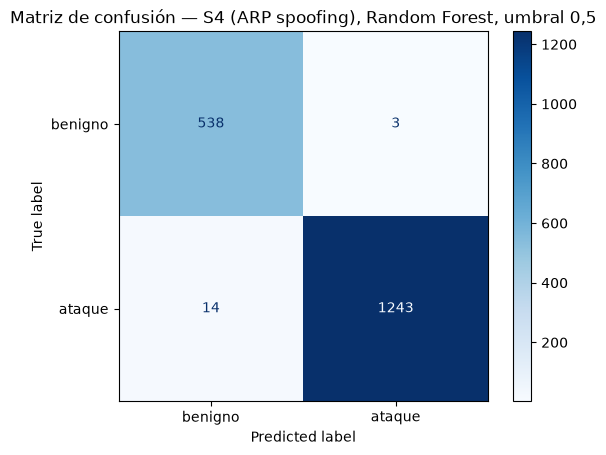

In [38]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["benigno", "ataque"], cmap="Blues"
)
plt.title("Matriz de confusión — S4 (ARP spoofing), Random Forest, umbral 0,5")
plt.show()


In [39]:
print(
    classification_report(
        y_test, pred_test, target_names=["benigno", "ataque"], digits=3
    )
)

              precision    recall  f1-score   support

     benigno      0.975     0.994     0.984       541
      ataque      0.998     0.989     0.993      1257

    accuracy                          0.991      1798
   macro avg      0.986     0.992     0.989      1798
weighted avg      0.991     0.991     0.991      1798



### Qué nos dicen los resultados de S4

- **Recall = 0,951:** detecta 1.195 de los 1.257 ataques; se le escapan 62.
- **Precisión del ataque = 0,972:** de las 1.229 filas que marcó como ataque, 1.195 realmente eran ataques.
- **Especificidad = 0,937:** reconoce como benignas 507 de las 541 filas benignas; marca 34 como falsas alarmas.
- **Exactitud = 0,947:** supera a la regla simple "decir ataque siempre", que obtiene 0,699 porque el 69,9 % de S4 son ataques.

También hay dos detalles importantes:

- La **precisión del benigno** es 0,891: de las 569 filas que el modelo deja pasar como benignas, 507 son benignas de verdad (62 FN frente a 507 TN).
- La **precisión depende de cuántos ataques haya** en el conjunto evaluado. Como S4 tiene muchos ataques, la precisión del ataque puede ser alta aunque el modelo deje escapar algunos.
- La exactitud en entrenamiento es 0,999 y en prueba 0,947: en este escenario el modelo generaliza un poco peor que en entrenamiento. En `S6` la brecha es enorme (0,999 contra 0,724), y esa diferencia entre escenarios es la que hay que explicar, no la del entrenamiento.

### Las mismas métricas, escenario por escenario

La lectura anterior fue para un fold. Esta tabla aplica las mismas definiciones a los ocho escenarios con el modelo que va a producción (Random Forest sobre `block_pca`, umbral 0,5). En `S0` no hay ataques: recall, precisión, F1, AUC y PR-AUC quedan vacíos y solo se mide la especificidad.


In [ ]:
# Mismas columnas que ya calculó el loop LOSo.
metricas_escenarios = [
    "filas", "ataques", "columnas",
    "AUC", "PR-AUC", "recall@1%", "recall@5%", "recall@10%",
    "precisión@0.5", "recall@0.5", "F1@0.5", "bal. acc", "especificidad",
]
tabla_escenarios = (
    resultados_bp["rf"][["fold"] + metricas_escenarios]
    .set_index("fold")
    .rename_axis("escenario")
)
display(tabla_escenarios.round(3))


,filas,ataques,columnas,AUC,PR-AUC,recall@1%,recall@5%,recall@10%,precisión@0.5,recall@0.5,F1@0.5,bal. acc,especificidad
escenario,,,,,,,,,,,,,
S0,1798,0,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.815
S1,1798,913,42,0.943,0.945,0.495,0.694,0.812,0.809,0.940,0.869,0.855,0.771
S1alt,1792,910,41,0.966,0.976,0.897,0.901,0.909,0.735,0.962,0.833,0.802,0.642
S2,1768,903,43,0.948,0.884,0.000,0.843,0.869,0.906,0.289,0.438,0.629,0.969
S3,1800,912,41,0.921,0.922,0.338,0.633,0.780,0.839,0.879,0.859,0.853,0.827
S4,1798,1257,37,0.991,0.996,0.990,0.990,0.990,0.998,0.989,0.993,0.992,0.994
S5,1800,1341,39,0.919,0.952,0.153,0.248,0.989,0.961,0.825,0.888,0.863,0.902
S6,1800,1350,42,0.977,0.992,0.554,0.955,0.964,0.989,0.705,0.823,0.840,0.976


### 4.1 ¿Qué pasa si cambiamos el umbral?

El umbral 0,5 convierte los puntajes en decisiones: si el puntaje alcanza o supera 0,5, la fila se marca como ataque. Ese valor es una regla de decisión, no una propiedad fija del modelo.

Si bajamos el umbral, más filas se marcan como ataques: suele subir el recall, pero también aumentan las falsas alarmas. La tabla muestra ese intercambio para S4.


In [41]:
filas = []
for umbral in (0.10, 0.30, 0.50, 0.70, 0.90):
    pred = (score_test >= umbral).astype(int)
    tn_u, fp_u, fn_u, tp_u = confusion_matrix(y_test, pred).ravel()
    filas.append(
        {
            "umbral": umbral,
            "TP": tp_u,
            "FP": fp_u,
            "FN": fn_u,
            "TN": tn_u,
            "recall": tp_u / (tp_u + fn_u) if (tp_u + fn_u) else np.nan,
            "especificidad": tn_u / (tn_u + fp_u) if (tn_u + fp_u) else np.nan,
            "precisión": tp_u / (tp_u + fp_u) if (tp_u + fp_u) else np.nan,
        }
    )

display(pd.DataFrame(filas).round(3))

,umbral,TP,FP,FN,TN,recall,especificidad,precisión
0,0.1,1257,410,0,131,1.000,0.242,0.754
1,0.3,1245,57,12,484,0.990,0.895,0.956
2,0.5,1243,3,14,538,0.989,0.994,0.998
3,0.7,956,3,301,538,0.761,0.994,0.997
4,0.9,182,0,1075,541,0.145,1.000,1.000


### 4.2 De dónde sale el recall de 0,951

La tabla muestra qué cambia al mover el umbral. El histograma muestra cómo se distribuyen los puntajes del modelo para filas benignas y para ataques, y dónde cae el umbral.

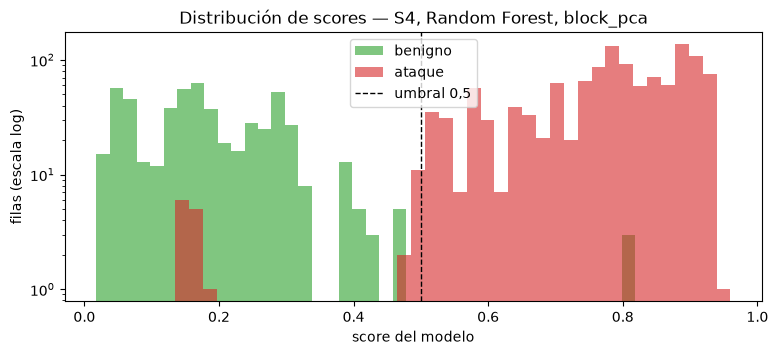

mediana benigno: 0.164
mediana ataque : 0.792
ataques con score < 0,5: 14 de 1257
benignos con score >= 0,5: 3 de 541


In [42]:
fig, eje = plt.subplots(figsize=(9, 3.5))
eje.hist(score_test[y_test == 0], bins=40, alpha=0.6, color="tab:green", label="benigno")
eje.hist(score_test[y_test == 1], bins=40, alpha=0.6, color="tab:red", label="ataque")
eje.axvline(0.5, color="black", ls="--", lw=1, label="umbral 0,5")
eje.set_xlabel("score del modelo")
eje.set_ylabel("filas (escala log)")
eje.set_yscale("log")
eje.set_title("Distribución de scores — S4, Random Forest, block_pca")
eje.legend()
plt.show()

print("mediana benigno:", round(float(np.median(score_test[y_test == 0])), 3))
print("mediana ataque :", round(float(np.median(score_test[y_test == 1])), 3))
print(
    "ataques con score < 0,5:",
    int(((score_test < 0.5) & (y_test == 1)).sum()),
    "de",
    int((y_test == 1).sum()),
)
print(
    "benignos con score >= 0,5:",
    int(((score_test >= 0.5) & (y_test == 0)).sum()),
    "de",
    int((y_test == 0).sum()),
)

La mediana del puntaje es 0,226 para las filas benignas y 0,772 para los ataques, y 62 ataques quedan por debajo de 0,5. Por eso el recall es 0,951: el modelo separa bien y el umbral cae en un hueco de la distribución.

El AUC (0,979) y el recall a umbral 0,5 (0,951) no coinciden exactamente, y en otros escenarios se separan más: en `S6` el AUC es 0,921 y el recall a 0,5 cae a 0,448, porque más ataques quedan del lado benigno del umbral. El AUC evalúa cómo se ordenan los puntajes en todos los umbrales; el recall de una tabla evalúa las decisiones tomadas con un umbral específico.

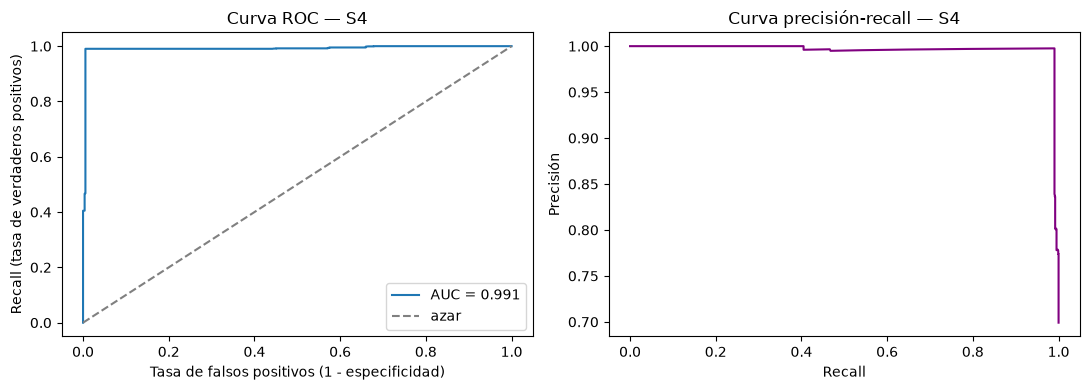

AUC: 0.991
recall aceptando 5 % de falsos positivos: 0.99
recall aceptando 1 % de falsos positivos: 0.99


In [43]:
fpr, tpr, umbrales = roc_curve(y_test, score_test)
auc_s4 = roc_auc_score(y_test, score_test)

precision_curva, recall_curva, _ = precision_recall_curve(y_test, score_test)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].plot(fpr, tpr, label=f"AUC = {auc_s4:.3f}")
ejes[0].plot([0, 1], [0, 1], "--", color="gray", label="azar")
ejes[0].set_title("Curva ROC — S4")
ejes[0].set_xlabel("Tasa de falsos positivos (1 - especificidad)")
ejes[0].set_ylabel("Recall (tasa de verdaderos positivos)")
ejes[0].legend()

ejes[1].plot(recall_curva, precision_curva, color="purple")
ejes[1].set_title("Curva precisión-recall — S4")
ejes[1].set_xlabel("Recall")
ejes[1].set_ylabel("Precisión")

plt.tight_layout()
plt.show()

print("AUC:", round(auc_s4, 3))
print("recall aceptando 5 % de falsos positivos:", round(recall_con_fpr(y_test, score_test, 0.05), 3))
print("recall aceptando 1 % de falsos positivos:", round(recall_con_fpr(y_test, score_test, 0.01), 3))

El **AUC** resume el orden de los puntajes: si elegimos al azar un ataque y un caso benigno, mide con qué frecuencia el ataque recibe un puntaje mayor. No fija un umbral y no significa “porcentaje de ataques detectados”.

El **recall@5 % FPR** responde otra pregunta: si permitimos que hasta el 5 % de las filas benignas se marquen como ataques, ¿qué proporción de los ataques detectamos? Ese 5 % limita la tasa de falsas alarmas; no garantiza una precisión superior al 95 %.


### 4.3 El fold S0 no tiene ataques

`S0` contiene solo filas benignas. Sin casos positivos no podemos calcular AUC, recall ni F1. Sí podemos medir la **especificidad**: qué proporción de las filas benignas el modelo reconoce correctamente.


In [44]:
y_s0 = detalle_bp["rf"]["S0"]["y_test"]
pred_s0 = detalle_bp["rf"]["S0"]["pred_test"]

tn, fp, fn, tp = confusion_matrix(y_s0, pred_s0).ravel()
print(f"S0 no tiene ataques -> TP={tp}, FN={fn}")
print("especificidad:", round(tn / (tn + fp), 3))
print("filas limpias marcadas como ataque:", int(fp), "de", len(y_s0))

S0 no tiene ataques -> TP=0, FN=0
especificidad: 0.815
filas limpias marcadas como ataque: 333 de 1798


Con `block_pca`, el modelo marca como ataque 887 de las 1.798 filas de `S0`: especificidad 0,507. Sin `Profile.*`, la transferencia a un escenario limpio no visto es pobre: casi la mitad del tráfico benigno dispara una falsa alarma.

Tampoco es una prueba de transferencia: el modelo sigue dependiendo del momento y del escenario a través de las variables eléctricas. La sección 4.12 del informe cuantifica esa dependencia.

Lo que queda claro acá es operativo: con el umbral 0,5, un escenario benigno nuevo produce 887 falsas alarmas cada 1.798 filas. Ese umbral necesita recalibración antes de usarse en planta; la elección de `block_pca` es sobre capacidad de detección, no sobre calibración.

## 5. Del cuaderno a producción

Hasta acá entrenamos y evaluamos dentro del notebook. En producción el modelo no se reentrena: viaja como un archivo. `python -m src.production --variant block_pca` guarda `modelos/supervised_blockpca.joblib`, que contiene la receta de features, el transformador `block_pca` ya ajustado, el umbral decidido en entrenamiento y el modelo entrenado.

Esta sección carga ese archivo y lo aplica a un CSV, sin volver a mirar las etiquetas.


In [45]:
import joblib
import subprocess

from src.features import detrend

try:
    paquete = joblib.load("modelos/supervised_blockpca.joblib")
except Exception as error:
    # El bundle se guardó con otra versión de scikit-learn: lo regeneramos acá mismo.
    print("el bundle guardado no abre con esta versión:", error)
    print("lo regeneramos con src/production.py...")
    subprocess.run(
        [sys.executable, "-m", "src.production", "--variant", "block_pca"], check=True
    )
    paquete = joblib.load("modelos/supervised_blockpca.joblib")

print("qué guarda el archivo:", list(paquete.keys()))
print("umbral:", paquete["threshold"], "| bloques:", len(paquete["block_pca"].blocks_))
print("columnas de entrada que espera:", len(paquete["block_pca"].columns_))


qué guarda el archivo: ['pipeline', 'detrend', 'window', 'threshold', 'reduce', 'block_pca']
umbral: 0.5 | bloques: 28
columnas de entrada que espera: 139


El paquete trae todo lo necesario para repetir el camino, en orden:

1. `detrend` y `window`: el rango móvil con el que se transformaron las variables.
2. `block_pca`: el transformador ajustado — imputación, filtro de varianza, bloques de correlación, escalado y PCA por bloque.
3. `pipeline`: el Random Forest entrenado sobre las componentes.
4. `threshold`: el punto de corte (0,5) con el que se leyeron todas las tablas de LOSO.

La probabilidad que devuelve el modelo se compara con ese umbral: si la supera, la fila se marca como ataque. Guardar el transformador ajustado es lo que hace que el archivo alcance: sin él habría que reagrupar y reajustar el PCA sobre datos nuevos, que es justo lo que la evaluación evitó.


In [46]:
# 1. Un escenario nuevo, tal como llega: un CSV con una fila por segundo.
nuevo = pd.read_csv("datasets/datasetS6.csv").assign(scenario="objetivo")
matrices_nuevo = build_matrices(nuevo, include_profile=False)

# 2. El mismo transformador del entrenamiento, tal como lo aplica src/predict.py.
X_nuevo = detrend(
    matrices_nuevo.X,
    matrices_nuevo.scenario,
    method=paquete["detrend"],
    window=paquete["window"],
)
X_nuevo = paquete["block_pca"].transform(X_nuevo)

# 3. Probabilidad de ataque por fila y decisión con el umbral guardado.
probabilidad = paquete["pipeline"].predict_proba(X_nuevo)[:, 1]
alerta = (probabilidad > paquete["threshold"]).astype(int)

print("filas:", len(alerta), "| columnas usadas:", X_nuevo.shape[1])
print(f"alertas: {alerta.sum():,} ({alerta.mean():.1%})")

filas: 1800 | columnas usadas: 40
alertas: 1,351 (75.1%)


In [47]:
vista = pd.DataFrame(
    {
        "probabilidad": probabilidad,
        "alerta": np.where(alerta == 1, "sí", "no"),
        "etiqueta_real": np.where(matrices_nuevo.y_binary == 1, "ataque", "benigno"),
    }
)

print("alerta contra etiqueta real (S6 completo):")
display(pd.crosstab(vista["etiqueta_real"], vista["alerta"], margins=True))

# Desde el primer ataque: ahí se ve la probabilidad cruzar el umbral.
primer_ataque = int(np.flatnonzero(matrices_nuevo.y_binary.to_numpy() == 1)[0])
print(f"primeras filas de ataque (desde la fila {primer_ataque}):")
display(vista.iloc[primer_ataque : primer_ataque + 8].round(3))


alerta contra etiqueta real (S6 completo):


alerta,no,sí,All
etiqueta_real,,,
ataque,0,1350,1350
benigno,449,1,450
All,449,1351,1800


primeras filas de ataque (desde la fila 438):


,probabilidad,alerta,etiqueta_real
438,0.570,sí,ataque
439,0.635,sí,ataque
440,0.674,sí,ataque
441,0.959,sí,ataque
442,0.977,sí,ataque
443,0.977,sí,ataque
444,0.986,sí,ataque
445,0.986,sí,ataque


**Lectura.** El modelo acierta 1.799 de 1.800 filas: marca los 1.350 ataques y deja pasar 449 de las 450 benignas. Eso no es detección, es memoria: el bundle se entrenó con S6 adentro. El contraste con el fold que deja S6 afuera —recall 0,448 y 745 ataques sin detectar— mide cuánto de ese acierto depende de haber visto el escenario.

La sección demuestra el **circuito** —archivo, CSV, transformación, puntaje, umbral, alerta—, no el rendimiento. El rendimiento honesto es el de LOSO: AUC 0,901, recall@5 % FPR 0,527 y especificidad 0,507 en `S0`.

Y queda el problema operativo: con el umbral 0,5, 1.351 filas de media hora de operación llegan a revisión. Un operador no ve una probabilidad, ve una alerta. Por eso la conclusión separa dos cosas: el detector sirve como priorizador, y el umbral necesita calibración adaptativa.

Los bundles conviven: `supervised.joblib` (132 features) es la referencia, `supervised_blockpca.joblib` (36 componentes) es la variante elegida y `supervised_reduced.joblib` (~10 columnas) queda como comparación. El no supervisado en producción se demuestra en la sección de no supervisado y mantiene la receta física.

## Conclusión

La validación cruzada aleatoria produce un resultado demasiado optimista porque filas vecinas y episodios relacionados quedan a ambos lados de la división, aunque los folds estén bien mezclados. LOSO es una evaluación más exigente, pero el AUC de 0,880 (base) o 0,901 (block_pca) tampoco demuestra por sí solo que el modelo detecte ataques sin usar pistas temporales.

Además, excluimos `Profile.*` porque es una fuga de identidad de escenario (congelado en `S0`, variable en S1–S6): inflaba el AUC con una señal que no es detección. Sin ese atajo, los números bajan a su valor honesto y la transferencia a un escenario limpio no visto queda pobre (especificidad 0,507 en `S0`).

**Para explicar el resultado en la defensa:**

1. La validación cruzada aleatoria de 8 folds da 0,9999, pero mezcla filas muy parecidas entre entrenamiento y prueba.
2. LOSO reserva un escenario entero; sus promedios son 0,880 con 132 variables, 0,811 con la receta física y 0,901 con `block_pca`.
3. Elegimos `block_pca` porque detecta más ataques cuando el punto de operación se fija por falsos positivos: recall@5 % FPR 0,527 contra 0,240 de la receta física, y 0,489 de las 132 sin reducir.
4. El costo está declarado: en el escenario limpio `S0` la especificidad es 0,507, es decir 887 falsas alarmas cada 1.798 filas. La elección es de capacidad de detección; el umbral queda pendiente de calibración.
5. `Profile.*` queda excluido por fuga: congelado en `S0` y variable en S1–S6, separa `S0` de los ataques con AUC 0,988 pero no separa ataque de benigno dentro de un escenario (AUC 0,36). El paper del dataset tampoco lo usa en su baseline de ocho features. El paper GRIDGUARD-AI tampoco lo usa: sus 141 columnas son los 28 parámetros de cada uno de los cinco medidores más el precio MQTT. Lo que sí incluye es `Substation-AC-Meter.realtime`, un reloj absoluto (sección 3.4).
6. Por eso no afirmamos que este modelo haya probado una detección eléctrica independiente del tiempo: sin `Profile.*` la transferencia a `S0` es pobre, lo que refuerza que el dataset no soporta detección entre escenarios.


## Revisión de esta sección frente a la consigna

La consigna pide selección de atributos, tratamiento del desbalanceo, validación cruzada e hiperparámetros; también pide métricas supervisadas por modelo y por predicción/clase, y un modelo supervisado mostrado en modo producción.

- **Incluido:** cuatro modelos (Random Forest, SVM, XGBoost y CatBoost), pesos que compensan el desbalanceo, evaluación LOSO, configuraciones fijas y métricas por modelo, por fold y por clase (matriz de confusión y reporte por clase en la sección 4).
- **Selección de atributos:** la receta física se compara con la importancia de Random Forest, con el filtro de correlación, con ACP (sección 2.3) y con ACP por bloques (sección 2.4), que es la que quedó. El ranking de importancia y la selección de las 15 variables se repiten dentro de cada fold, usando solo los datos de entrenamiento. Queda sin implementar RFE: la consigna nombra tres métodos alternativos y acá se cubren dos, con la medición de por qué el ACP global pierde.
- **Hiperparámetros:** se muestran las configuraciones de los cuatro modelos y se agrega una búsqueda anidada dentro de LOSO (`LeaveOneGroupOut` como validación interna del fold de entrenamiento), que optimiza recall@5 % FPR y nunca usa el escenario de prueba. El control muestra que las cuatro combinaciones de la grilla no superan a la configuración fija y que la diferencia es menor que la variación entre escenarios.
- **Modo producción:** la sección 5 carga el bundle `supervised_blockpca.joblib`, lo aplica a un CSV y muestra el puntaje, el umbral y el conteo de alertas sin reentrenar. El transformador `block_pca` viaja dentro del archivo, así que la reducción se reproduce sin reajustarla.
